<a href="https://colab.research.google.com/github/Yashji12-matrix/FIRST/blob/main/maize_extreme_transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Extreme-year-aware transfer learning for maize yield, US corn to sub-Saharan Africa

A model trained on US county corn can be fine-tuned on a few years of African district data and works fine in ordinary
years. The years that matter, droughts and heat waves, are the ones it tends to get wrong. This notebook asks whether we can
do better there by (A) making the loss care more about severe anomalies and (B) giving more weight to US counties whose
climate resembles the African target, and whether conformal intervals (D) can still be trusted in those years.

It runs the whole project on real data, from download to conclusion: setup, data loading, cleaning and merging, EDA, features
and splits, models, experiment, progress plots, shortfall classification, uncertainty, an optional Transformer, and a
conclusion written from your own numbers.

Where the data come from: HarvestStat Africa on Dryad (<https://doi.org/10.5061/dryad.vq83bk42w>, you click through to download it,
paper at <https://doi.org/10.1038/s41597-025-05001-z>), USDA NASS QuickStats (free key at <https://quickstats.nass.usda.gov/api>)
and NASA POWER (<https://power.larc.nasa.gov/>).

A caution before you start. The download code follows the published formats of these services and was tested on local
stand-ins that mimic them, not on the live services, so expect to fix one small thing on the first run. The numbers in the
conclusion are computed from your run; nothing is hard-coded.

## 0. Setup

In [1]:
# Install only what is missing (works on Colab and locally). geopandas is only needed to read the boundary file.
import importlib.util, subprocess, sys
_need = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
         "matplotlib": "matplotlib", "requests": "requests"}
_missing = [pip for mod, pip in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
if importlib.util.find_spec("geopandas") is None:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geopandas", "pyogrio"])
    except Exception as e:
        print("geopandas could not be installed (", e, ") - supply a centroid CSV instead, see the config cell.")
print("environment ready")

environment ready


In [2]:
import argparse, base64, getpass, io, json, math, os, sys, time, warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import asdict, dataclass, field, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

try:
    from IPython.display import display
except ImportError:          # plain Python (for testing outside Jupyter)
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 160, "display.float_format", "{:.3f}".format)

In [3]:
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"


MAGENTA, GREEN, VIOLET, RED = "#e87ba4", "#008300", "#6250d6", "#e34948"


INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"


GRID, SURFACE, GREY = "#e1e0d9", "#fcfcfb", "#b9b8b0"


SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#5598e7", "#256abf", "#184f95", "#0d366b"]


SEASON_MONTHS = 6  # months in the growing-season window, counted from planting


BU_AC_TO_T_HA = 0.06277  # 1 bushel/acre of corn (56 lb/bu) in tonnes per hectare


DEFAULT_US_STATES = "IA,IL,IN,OH,MO,MN,WI,MI,KS,SD,ND,KY,TN,TX,OK,PA"

### Configuration
Everything you might want to change is in the next cells. Set `QUICK = True` first: it runs a small slice in a few minutes, which is
enough to find out whether every download and every cell works. Then switch it to `False` for the real run.

In [4]:
@dataclass
class Cfg:
    """Every setting in one place. Change things here, not deep in the code."""

    # --- data ---------------------------------------------------------------
    cache: str = "cache"          # downloads and processed tables are kept here
    year0: int = 1982             # first harvest year (NASA POWER daily starts 1981)
    year1: int = 2022             # last harvest year (HarvestStat ends 2022)
    us_states: str = DEFAULT_US_STATES   # mostly rain-fed states; irrigated Nebraska left out
    us_plant_month: int = 5       # corn planting month used for the US window
    max_src_counties: int = 0     # 0 = all; otherwise a random subset (speed)
    target_countries: str = ""    # comma list of names or ISO-2 codes; "" = all
    maize_regex: str = "maize|corn"      # which HarvestStat `product` values count as maize
    drop_qc_outliers: bool = False       # drop HarvestStat qc_flag == 1 (see notes above)
    max_tgt_yield: float = 12.0   # t/ha, above this a target value is treated as an error
    min_years_unit: int = 12      # a district needs this many years to get a trend
    hot_thr: float = 32.0         # Tmax (deg C) above which a day counts as a hot day
    grid_deg: float = 0.5         # weather grid snapping (NASA POWER resolution)
    workers: int = 3              # parallel weather downloads (be polite to the API)
    # --- experiment layout ----------------------------------------------------
    seed: int = 7                 # master seed (everything is reproducible)
    n_reps: int = 20              # repetitions (different random labelled years / inits)
    ft_sizes: tuple = (3, 5, 8)   # number of labelled target YEARS for fine-tuning
    main_ft: int = 5              # which size is the headline setting
    n_cal_years: int = 5          # years kept aside to calibrate intervals
    n_val_years: int = 3          # years used for early stopping during fine-tuning
    extreme_frac: float = 0.18    # share of each country's years treated as extreme
    min_country_years: int = 10   # a country needs this many years to define extremes
    min_units_cy: int = 3         # a country-year needs this many districts
    min_rows_year: int = 25       # a calendar year needs this many normal rows to be sampled
    shortfall_thr: float = -0.15  # anomaly below this = "shortfall"
    detrend: str = "full"         # 'full' = trend from all years; 'train' = fine-tune years only
    # --- network ---------------------------------------------------------------
    hidden: tuple = (64, 32)
    pre_epochs: int = 40
    ft_epochs: int = 80
    pre_lr: float = 2e-3
    ft_lr: float = 5e-4
    batch: int = 256
    weight_decay: float = 1e-4
    l2sp: float = 1e-2            # fine-tune penalty keeping weights near pretrained
    huber_delta: float = 1.0
    use_static: bool = True       # feed district climate descriptors to the net
    # --- method A: stress-weighted loss -------------------------------------------
    lam: float = 1.5              # strength of the extra weight on extreme anomalies
    gamma: float = 1.5            # how sharply weight grows with |z|
    clip_c: float = 3.0           # |z| beyond this adds no extra weight
    kappa: float = 1.5            # extra factor for shortfalls (negative anomalies)
    # --- method B: regime-matched source weights ----------------------------------
    k_nn: int = 5                 # nearest target districts used for similarity
    tau_scale: float = 1.0        # kernel width relative to the median distance
    w_clip: float = 4.0           # max weight relative to the mean
    # --- sensitivity sweep ----------------------------------------------------------
    sweep_lams: tuple = (0.0, 0.5, 1.5, 3.0, 6.0)
    sweep_reps: int = 6
    # --- housekeeping ----------------------------------------------------------------
    out: str = "outputs"


@dataclass
class Panel:
    """One region as a long table: a row per (district, harvest year)."""

    name: str
    dist: np.ndarray      # (N,) integer district/unit id
    country: np.ndarray   # (N,) integer country id
    year: np.ndarray      # (N,) harvest year
    wx: np.ndarray        # (N, M, 3) monthly [rain_mm, tmax_c, hot_days], months since planting
    y: np.ndarray         # (N,) yield in t/ha
    country_names: tuple = ()   # names for the integer country ids

In [5]:
# ------------------------------- YOUR SETTINGS ---------------------------------
QUICK = False                         # True = small slice, few repetitions (smoke test)

# Files you download once from Dryad (https://doi.org/10.5061/dryad.vq83bk42w):
HARVESTSTAT_CSV      = "hvstat_africa_data_v1.2.csv"
BOUNDARIES_GPKG      = "hvstat_africa_boundary_v1.2.gpkg"
# Optional fallbacks if you cannot use geopandas / the Census download:
TARGET_CENTROIDS_CSV = ""             # CSV with columns fnid,lat,lon
COUNTY_CENTROIDS_CSV = ""             # CSV with columns fips,lat,lon

cfg = Cfg(
    out="outputs", cache="cache",
    target_countries="",              # e.g. "Kenya,Zambia,Malawi" to narrow the target (faster)
    us_states=DEFAULT_US_STATES,      # mostly rain-fed US states
    drop_qc_outliers=False,           # keep HarvestStat outlier-flagged values (droughts can look like outliers)
    n_reps=20, sweep_reps=6,
)
if QUICK:
    cfg = replace(cfg, n_reps=3, sweep_reps=2, pre_epochs=12, ft_epochs=25, max_src_counties=250,
                  sweep_lams=(0.0, 1.5, 4.0))
os.makedirs(cfg.out, exist_ok=True)
IN_COLAB = "google.colab" in sys.modules

def ensure_file(path, label):
    """Colab: offer an upload dialog for a missing file. Local: print where to get it."""
    if not path or os.path.exists(path):
        return path
    if IN_COLAB:
        from google.colab import files
        print(f"Please upload {label} ({path})")
        up = files.upload()
        if up:
            os.replace(next(iter(up)), path)
        return path
    raise FileNotFoundError(f"{label} not found at {path!r}. Download it from https://doi.org/10.5061/dryad.vq83bk42w "
                            "and put it next to this notebook (or edit the path above).")

# NASS key: environment variable, else a prompt (only needed the first time; downloads are cached).
if not os.environ.get("NASS_API_KEY") and not os.path.exists(os.path.join(cfg.cache, "nass_corn_county.csv")):
    os.environ["NASS_API_KEY"] = getpass.getpass("USDA NASS API key (https://quickstats.nass.usda.gov/api): ")
print("configuration ready:", {k: v for k, v in asdict(cfg).items() if k in ("n_reps", "ft_sizes", "main_ft", "extreme_frac", "lam")})

USDA NASS API key (https://quickstats.nass.usda.gov/api): ··········
configuration ready: {'n_reps': 20, 'ft_sizes': (3, 5, 8), 'main_ft': 5, 'extreme_frac': 0.18, 'lam': 1.5}


## 1. Data layer
All network calls go through one function that retries and caches to disk, so nothing is downloaded twice. Target yields come from
HarvestStat Africa (district level, 1980 to 2022). Source yields come from USDA NASS county corn for grain, converted from bushels per
acre to t/ha. Weather for both regions is NASA POWER daily rain and maximum temperature, which keeps the transfer from being confounded by
two different weather products. Daily values are summarised as six months, counted from each row's planting month.

In [6]:
def log(msg):
    print(msg, flush=True)


def _requests():
    try:
        import requests
        return requests
    except ImportError:
        sys.exit("This step needs the `requests` package: pip install requests")


def _fetch(url, params, binary, retries=6, timeout=180):
    """GET with a few retries; returns parsed JSON, or raw bytes if binary=True."""
    req = _requests()
    last = None
    for attempt in range(retries):
        try:
            r = req.get(url, params=params, timeout=timeout)
            if r.status_code == 200:
                return r.content if binary else r.json()
            if r.status_code in (429, 500, 502, 503, 504):
                last = f"HTTP {r.status_code}"
                time.sleep(2 ** attempt)
                continue
            raise RuntimeError(f"HTTP {r.status_code} from {r.url}: {r.text[:300]}")
        except req.RequestException as e:  # network hiccup, wait and try again
            last = repr(e)
            time.sleep(2 ** attempt)
    raise RuntimeError(f"Giving up on {url} after {retries} tries ({last})")


def http_json(url, params=None, cache_file=None):
    if cache_file and os.path.exists(cache_file):
        with open(cache_file, "r", encoding="utf-8") as f:
            return json.load(f)
    data = _fetch(url, params, binary=False)
    if cache_file:
        os.makedirs(os.path.dirname(cache_file), exist_ok=True)
        with open(cache_file, "w", encoding="utf-8") as f:
            json.dump(data, f)
    return data


def http_bytes(url, cache_file=None):
    if cache_file and os.path.exists(cache_file):
        with open(cache_file, "rb") as f:
            return f.read()
    data = _fetch(url, None, binary=True)
    if cache_file:
        os.makedirs(os.path.dirname(cache_file), exist_ok=True)
        with open(cache_file, "wb") as f:
            f.write(data)
    return data


def snap(x, deg):
    """Round a coordinate to the weather grid so neighbouring districts share one download."""
    return round(round(float(x) / deg) * deg, 4)


NASS_URL = "https://quickstats.nass.usda.gov/api/api_GET/"


GAZETTEER_URL = ("https://www2.census.gov/geo/docs/maps-data/data/gazetteer/"
                 "2020_Gazetteer/2020_Gaz_counties_national.zip")


def fetch_nass_yields(cfg: Cfg):
    """County corn-for-grain yields from NASS, one request per year, converted to t/ha.

    "(D)" (suppressed) values and the "other counties" code 998 are dropped."""
    cache_csv = os.path.join(cfg.cache, "nass_corn_county.csv")
    if os.path.exists(cache_csv):
        return pd.read_csv(cache_csv, dtype={"fips": str})
    key = os.environ.get("NASS_API_KEY")
    if not key:
        sys.exit("Set NASS_API_KEY (free: https://quickstats.nass.usda.gov/api) or place a "
                 f"ready table at {cache_csv} with columns fips,state,year,yield_tha.")
    states = {s.strip().upper() for s in cfg.us_states.split(",") if s.strip()}
    frames = []
    for yr in range(cfg.year0, cfg.year1 + 1):
        params = dict(key=key, source_desc="SURVEY", sector_desc="CROPS", commodity_desc="CORN",
                      statisticcat_desc="YIELD", agg_level_desc="COUNTY", year=yr, format="JSON",
                      short_desc="CORN, GRAIN - YIELD, MEASURED IN BU / ACRE")
        js = http_json(NASS_URL, params, os.path.join(cfg.cache, "nass_raw", f"{yr}.json"))
        rows = js.get("data", [])
        if not rows:
            log(f"  NASS {yr}: no rows returned ({js.get('error')})")
            continue
        d = pd.DataFrame(rows)
        frames.append(d)
        if yr in (cfg.year0, cfg.year1):
            log(f"  NASS {yr}: {len(d)} county rows (all years are downloaded and cached)")
    if not frames:
        sys.exit("NASS returned nothing. Check the API key and your connection.")
    d = pd.concat(frames, ignore_index=True)
    d = d[d["state_alpha"].isin(states) & (d["county_code"].astype(str) != "998")]
    val = pd.to_numeric(d["Value"].astype(str).str.replace(",", ""), errors="coerce")
    out = pd.DataFrame({
        "fips": d["state_fips_code"].astype(str).str.zfill(2) + d["county_code"].astype(str).str.zfill(3),
        "state": d["state_alpha"], "year": d["year"].astype(int), "yield_tha": val * BU_AC_TO_T_HA})
    out = out.dropna().drop_duplicates(["fips", "year"])
    out = out[out.yield_tha > 0.5]
    os.makedirs(cfg.cache, exist_ok=True)
    out.to_csv(cache_csv, index=False)
    return out


def fetch_county_centroids(cfg: Cfg, override_csv=""):
    """County centre points (lat/lon) from the Census gazetteer, or from your own CSV."""
    if override_csv:
        d = pd.read_csv(override_csv, dtype={"fips": str})
        return d[["fips", "lat", "lon"]]
    import zipfile
    raw = http_bytes(GAZETTEER_URL, os.path.join(cfg.cache, "gazetteer_counties.zip"))
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        name = [n for n in z.namelist() if n.lower().endswith(".txt")][0]
        d = pd.read_csv(z.open(name), sep="\t", dtype={"GEOID": str})
    d.columns = [c.strip() for c in d.columns]
    return pd.DataFrame({"fips": d["GEOID"].str.zfill(5), "lat": d["INTPTLAT"].astype(float),
                         "lon": d["INTPTLONG"].astype(float)})


HS_COLS = ["fnid", "country", "country_code", "admin_1", "product", "season_name",
           "planting_year", "planting_month", "harvest_year", "harvest_month",
           "crop_production_system", "qc_flag", "area", "production", "yield"]


def load_harveststat(csv_path, cfg: Cfg, funnel=None):
    """Turn the HarvestStat Africa file into one maize row per unit and harvest year.

    Keeps maize products, drops irrigated systems, optionally drops QC-flagged
    outliers, throws out impossible yields, gives each unit a single planting month
    and area-weights rows when several maize products sit in the same unit-year.
    Prints what it matched so you can check it against the real file."""
    df = pd.read_csv(csv_path, low_memory=False)
    missing = [c for c in HS_COLS if c not in df.columns]
    if missing:
        sys.exit(f"HarvestStat file lacks columns {missing}. Found: {list(df.columns)}")
    n0 = len(df)
    fun = (lambda k, d: funnel.append((k, len(d)))) if funnel is not None else (lambda k, d: None)
    fun('raw HarvestStat rows (all crops)', df)
    is_maize = df["product"].astype(str).str.contains(cfg.maize_regex, case=False, regex=True)
    log("  maize products matched (check these!):")
    for k, v in df.loc[is_maize, "product"].value_counts().items():
        log(f"     {v:7d}  {k}")
    df = df[is_maize]
    fun('maize products', df)
    irrig = df["crop_production_system"].astype(str).str.contains("irrig", case=False)
    log(f"  production systems: {df['crop_production_system'].value_counts().to_dict()}  "
        f"(dropping {int(irrig.sum())} irrigated rows)")
    df = df[~irrig]
    fun('rain-fed / not irrigated', df)
    log(f"  qc_flag counts: {df['qc_flag'].value_counts().to_dict()}  "
        f"({'dropping' if cfg.drop_qc_outliers else 'keeping'} outlier-flagged rows)")
    if cfg.drop_qc_outliers:
        df = df[df["qc_flag"] != 1]
    fun('after QC filter', df)
    if cfg.target_countries.strip():
        want = {c.strip().lower() for c in cfg.target_countries.split(",") if c.strip()}
        df = df[df["country"].str.lower().isin(want) | df["country_code"].str.lower().isin(want)]
    df = df.dropna(subset=["yield", "harvest_year"])
    df = df[(df["yield"] > 0) & (df["yield"] <= cfg.max_tgt_yield)]
    df = df[(df["harvest_year"] >= cfg.year0) & (df["harvest_year"] <= cfg.year1)]
    fun('valid yield, year range, country filter', df)
    # planting month: fill gaps with the (country, season) mode; then one month per unit
    df["season_name"] = df["season_name"].fillna("main").astype(str)
    df["unit"] = df["fnid"].astype(str) + "|" + df["season_name"]
    mode = lambda s: s.mode().iloc[0] if s.notna().any() else np.nan
    pm_cs = df.groupby(["country_code", "season_name"])["planting_month"].transform(mode)
    df["planting_month"] = df["planting_month"].fillna(pm_cs)
    df = df.dropna(subset=["planting_month"])
    fun('planting month known', df)
    df["pm_unit"] = df.groupby("unit")["planting_month"].transform(mode).astype(int)
    # planting year: from the file, else derived from harvest year and months
    py = df["planting_year"]
    derived = df["harvest_year"] - (df["pm_unit"] > df["harvest_month"].fillna(12)).astype(int)
    df["py"] = py.fillna(derived).astype(int)
    # area-weighted mean yield per unit-year (several maize products may coexist)
    area = df["area"].where(df["area"] > 0, 1.0).fillna(1.0)
    df["_w"], df["_wy"] = area, area * df["yield"]
    g = df.groupby(["unit", "fnid", "country", "country_code", "pm_unit", "harvest_year"],
                   as_index=False).agg(_w=("_w", "sum"), _wy=("_wy", "sum"), py=("py", "min"))
    g["yield_tha"] = g["_wy"] / g["_w"]
    g = g.rename(columns={"pm_unit": "plant_month", "harvest_year": "year", "py": "plant_year"})
    fun('one row per unit-year (aggregated)', g)
    log(f"  HarvestStat: {n0} raw rows -> {len(g)} maize unit-years in "
        f"{g['unit'].nunique()} units, {g['country'].nunique()} countries")
    return g[["unit", "fnid", "country", "plant_month", "plant_year", "year", "yield_tha"]]


def target_centroids(boundaries, centroid_csv, fnids):
    """Look up each district's lat/lon, from the boundary file (needs geopandas) or a CSV."""
    if centroid_csv:
        d = pd.read_csv(centroid_csv)
        return d[["fnid", "lat", "lon"]].drop_duplicates("fnid")
    try:
        import geopandas as gpd
    except ImportError:
        sys.exit("Reading the boundary file needs geopandas (pip install geopandas pyogrio), "
                 "or pass --target-centroids a CSV with columns fnid,lat,lon.")
    gdf = gpd.read_file(boundaries)
    if gdf.crs is not None and gdf.crs.to_epsg() != 4326:
        gdf = gdf.to_crs(4326)
    pts = gdf.geometry.representative_point()
    d = pd.DataFrame({"fnid": gdf["fnid"].astype(str), "lat": pts.y.values, "lon": pts.x.values})
    return d[d["fnid"].isin(set(fnids))].drop_duplicates("fnid")


POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"


def fetch_weather_cell(lat, lon, cfg: Cfg):
    """Daily rain (mm) and Tmax (C) for one grid cell, cached as a small .npz.

    If you would rather use CHIRPS or ERA5, this is the one function to swap out. It must
    return two float arrays (rain, tmax), one value per day from 1 Jan of year0-1 to
    31 Dec of year1, with NaN where data are missing. The extra first year is there
    because a crop planted in October belongs to the previous calendar year."""
    start, end = f"{cfg.year0 - 1}0101", f"{cfg.year1}1231"
    fn = os.path.join(cfg.cache, "power", f"{lat:.3f}_{lon:.3f}_{start}_{end}.npz")
    if os.path.exists(fn):
        z = np.load(fn)
        return z["rain"], z["tmax"]
    params = dict(parameters="PRECTOTCORR,T2M_MAX", community="AG", latitude=lat, longitude=lon,
                  start=start, end=end, format="JSON")
    js = _fetch(POWER_URL, params, binary=False)
    par = js["properties"]["parameter"]
    days = pd.date_range(f"{cfg.year0 - 1}-01-01", f"{cfg.year1}-12-31", freq="D")
    def arr(name):
        s = pd.Series(par[name])
        s.index = pd.to_datetime(s.index, format="%Y%m%d")
        a = np.array(s.reindex(days), dtype=np.float32)   # writable copy
        a[a <= -900] = np.nan          # POWER's fill value is -999
        return a
    rain, tmax = arr("PRECTOTCORR"), arr("T2M_MAX")
    os.makedirs(os.path.dirname(fn), exist_ok=True)
    np.savez_compressed(fn, rain=rain, tmax=tmax)
    return rain, tmax


def monthly_features(rain, tmax, cfg: Cfg):
    """Daily series to monthly [rain total, mean Tmax, hot days], shape (years, 12, 3).

    Year index 0 is year0-1. Months with fewer than 25 valid days become NaN."""
    days = pd.date_range(f"{cfg.year0 - 1}-01-01", f"{cfg.year1}-12-31", freq="D")
    df = pd.DataFrame({"r": rain, "t": tmax, "hot": (tmax >= cfg.hot_thr).astype(float)}, index=days)
    df.loc[df["t"].isna(), "hot"] = np.nan
    g = df.groupby([df.index.year, df.index.month])
    n_ok = g["r"].count()
    out = pd.DataFrame({"rain": g["r"].sum(min_count=1), "tmax": g["t"].mean(), "hot": g["hot"].sum(min_count=1)})
    out[n_ok < 25] = np.nan
    ny = cfg.year1 - cfg.year0 + 2
    arr = np.full((ny, 12, 3), np.nan, dtype=np.float32)
    for (yy, mm), row in out.iterrows():
        arr[yy - (cfg.year0 - 1), mm - 1] = row.to_numpy()
    return arr


def weather_for_cells(cells, cfg: Cfg):
    """Fetch (or load from cache) weather for every grid cell, a few downloads at a time."""
    todo = sorted(set(cells))
    log(f"  weather: {len(todo)} grid cells (cached ones are instant)")
    res, failed, t0 = {}, [], time.time()

    def work(c):
        rain, tmax = fetch_weather_cell(c[0], c[1], cfg)
        return c, monthly_features(rain, tmax, cfg)

    with ThreadPoolExecutor(max_workers=max(1, cfg.workers)) as ex:
        futs = {ex.submit(work, c): c for c in todo}
        for i, f in enumerate(as_completed(futs), 1):
            try:
                c, a = f.result()
                res[c] = a
            except Exception as e:  # keep going and report the failures at the end
                failed.append((futs[f], repr(e)[:120]))
            if i % 50 == 0 or i == len(todo):
                log(f"    {i}/{len(todo)} cells ({time.time() - t0:.0f}s)")
    if failed:
        log(f"  WARNING: {len(failed)} cells failed (first: {failed[0]}). Rerun to retry them.")
        if len(failed) > 0.2 * len(todo):
            sys.exit("More than 20 percent of weather downloads failed; check connection / API status.")
    return res


def build_panel(name, recs, wx_by_cell, cfg: Cfg):
    """Attach weather to each yield record and return a Panel.

    The six weather months start at the planting month, so month 3 is roughly
    flowering in both regions regardless of the calendar."""
    cells = sorted(wx_by_cell)
    cidx = {c: i for i, c in enumerate(cells)}
    W = np.stack([wx_by_cell[c] for c in cells])                 # (cells, years+1, 12, 3)
    r = recs[recs["cell"].isin(cidx)].copy()
    ci = r["cell"].map(cidx).to_numpy()
    m = (r["plant_month"].to_numpy(int) - 1)[:, None] + np.arange(SEASON_MONTHS)[None, :]
    yy = (r["plant_year"].to_numpy(int) - (cfg.year0 - 1))[:, None] + m // 12
    ok = (yy >= 0) & (yy < W.shape[1])
    wx = W[ci[:, None], np.clip(yy, 0, W.shape[1] - 1), m % 12]  # (N, 6, 3)
    wx[~ok] = np.nan
    good = np.isfinite(wx).all(axis=(1, 2))
    r, wx = r[good].reset_index(drop=True), wx[good]
    # a unit needs enough years to fit a trend
    cnt = r.groupby("unit")["year"].transform("count")
    keep = (cnt >= cfg.min_years_unit).to_numpy()
    r, wx = r[keep].reset_index(drop=True), wx[keep]
    dist, _ = pd.factorize(r["unit"])
    ctry, cnames = pd.factorize(r["country"])
    return Panel(name, dist, ctry, r["year"].to_numpy(int), wx, r["yield_tha"].to_numpy(float),
                 tuple(cnames))


def build_data(cfg: Cfg, harveststat, boundaries, centroid_csv="", county_centroid_csv="", funnel=None):
    """The whole data stage. Returns the source Panel, the target Panel and an audit table."""
    os.makedirs(cfg.cache, exist_ok=True)
    log("== Data: target (HarvestStat Africa)")
    tgt = load_harveststat(harveststat, cfg, funnel)
    cen = target_centroids(boundaries, centroid_csv, set(tgt["fnid"]))
    tgt = tgt.merge(cen, on="fnid", how="inner")
    log(f"  {tgt['unit'].nunique()} units have boundary coordinates")
    if funnel is not None:
        funnel.append(('with boundary coordinates', len(tgt)))
    tgt["cell"] = list(zip(tgt["lat"].map(lambda v: snap(v, cfg.grid_deg)),
                           tgt["lon"].map(lambda v: snap(v, cfg.grid_deg))))

    log("== Data: source (USDA NASS county corn)")
    src = fetch_nass_yields(cfg)
    src = src[(src.year >= cfg.year0) & (src.year <= cfg.year1)]
    cc = fetch_county_centroids(cfg, county_centroid_csv)
    src = src.merge(cc, on="fips", how="inner")
    cnt = src.groupby("fips")["year"].transform("count")
    src = src[cnt >= cfg.min_years_unit]
    if cfg.max_src_counties and src["fips"].nunique() > cfg.max_src_counties:
        keep = np.random.default_rng(cfg.seed).choice(src["fips"].unique(), cfg.max_src_counties, replace=False)
        src = src[src["fips"].isin(keep)]
    src = src.rename(columns={"fips": "unit", "state": "country"})
    src["plant_month"], src["plant_year"] = cfg.us_plant_month, src["year"]
    src["cell"] = list(zip(src["lat"].map(lambda v: snap(v, cfg.grid_deg)),
                           src["lon"].map(lambda v: snap(v, cfg.grid_deg))))
    log(f"  {src['unit'].nunique()} counties, {len(src)} county-years")

    log("== Data: weather (NASA POWER)")
    wx = weather_for_cells(list(tgt["cell"]) + list(src["cell"]), cfg)
    P_src = build_panel("Source (US corn)", src, wx, cfg)
    P_tgt = build_panel("Target (SSA maize)", tgt, wx, cfg)
    if funnel is not None:
        funnel.append(('complete weather + enough years per unit (final)', len(P_tgt.y)))
    audit = data_audit(P_src, P_tgt)
    log(f"  final source: {len(P_src.y)} rows / {len(np.unique(P_src.dist))} counties")
    log(f"  final target: {len(P_tgt.y)} rows / {len(np.unique(P_tgt.dist))} units / "
        f"{len(P_tgt.country_names)} countries")
    return P_src, P_tgt, audit


def data_audit(src: Panel, tgt: Panel):
    """Coverage and yield level per country (or per state for the source)."""
    rows = []
    for p in (src, tgt):
        for ci, nm in enumerate(p.country_names):
            m = p.country == ci
            rows.append(dict(region=p.name, country=nm, units=len(np.unique(p.dist[m])), rows=int(m.sum()),
                             first_year=int(p.year[m].min()), last_year=int(p.year[m].max()),
                             mean_yield_tha=round(float(p.y[m].mean()), 2),
                             sd_yield_tha=round(float(p.y[m].std()), 2)))
    return pd.DataFrame(rows)

## 2. Load, clean and merge

In [7]:
ensure_file(HARVESTSTAT_CSV, "the HarvestStat Africa data CSV")
if not TARGET_CENTROIDS_CSV:
    ensure_file(BOUNDARIES_GPKG, "the HarvestStat boundary GeoPackage")

FUNNEL = []
src, tgt, audit = build_data(cfg, HARVESTSTAT_CSV, BOUNDARIES_GPKG, TARGET_CENTROIDS_CSV, COUNTY_CENTROIDS_CSV, FUNNEL)
audit.to_csv(os.path.join(cfg.out, "data_audit.csv"), index=False)

== Data: target (HarvestStat Africa)
  maize products matched (check these!):
       25780  Maize
         351  Maize (Yellow)
  production systems: {'All (PS)': 15161, 'none': 7491, 'Rainfed (PS)': 1767, 'Commercial (PS)': 696, 'irrigated': 416, 'Communal (PS)': 152, 'Plaine/Bas-fond irrigated (PS)': 122, 'surface water': 82, 'parastatal recessional': 60, 'dieri': 44, 'dam irrigation': 42, 'CA (PS)': 16, 'A1 (PS)': 16, 'A2 (PS)': 16, 'SSCF (PS)': 16, 'OR (PS)': 16, 'LSCF (PS)': 15, 'recessional (PS)': 3}  (dropping 580 irrigated rows)
  qc_flag counts: {0: 25247, 2: 226, 1: 78}  (keeping outlier-flagged rows)
  HarvestStat: 217487 raw rows -> 21670 maize unit-years in 1417 units, 29 countries
  1417 units have boundary coordinates
== Data: source (USDA NASS county corn)
  NASS 1982: 2432 county rows (all years are downloaded and cached)
  NASS 2022: 1543 county rows (all years are downloaded and cached)
  1331 counties, 48417 county-years
== Data: weather (NASA POWER)
  weather: 1673 

Cleaning log: how many target rows survive each step. Watch for a step that drops far more than you'd expect.

,step,rows,dropped
0,raw HarvestStat rows (all crops),217487,0
1,maize products,26131,191356
2,rain-fed / not irrigated,25551,580
3,after QC filter,25551,0
4,"valid yield, year range, country filter",22083,3468
5,planting month known,22083,0
6,one row per unit-year (aggregated),21670,413
7,with boundary coordinates,21670,0
8,complete weather + enough years per unit (final),19143,2527


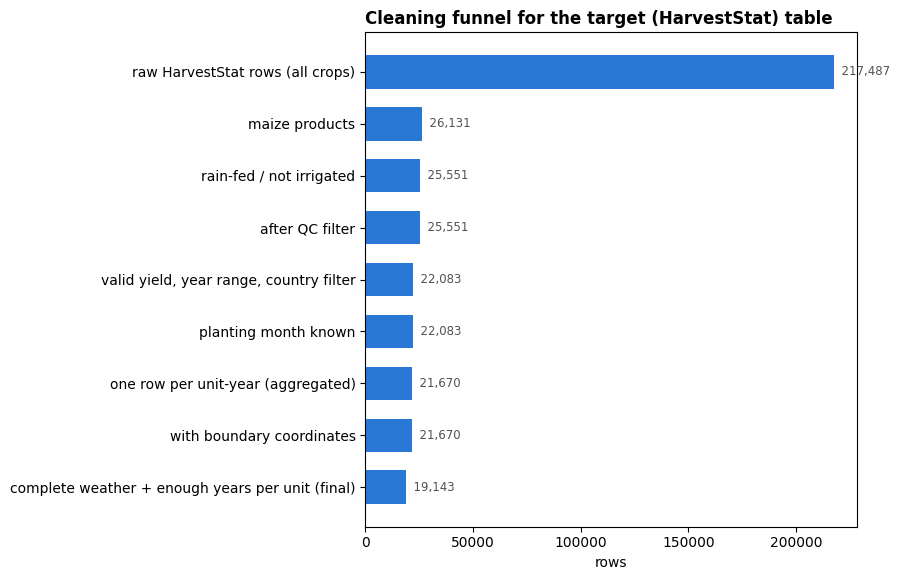

,region,country,units,rows,first_year,last_year,mean_yield_tha,sd_yield_tha
0,Source (US corn),IL,102,4036,1982,2022,9.040,2.490
1,Source (US corn),IN,92,3579,1982,2022,8.780,2.060
2,Source (US corn),IA,94,3809,1982,2022,9.330,2.320
3,Source (US corn),KS,105,3786,1982,2022,7.220,2.370
4,Source (US corn),KY,107,3782,1982,2022,7.230,2.230
5,Source (US corn),MI,70,2547,1982,2022,7.220,1.950
6,Source (US corn),MN,74,2852,1982,2022,8.240,2.530
7,Source (US corn),MO,99,3531,1982,2022,7.130,2.180
8,Source (US corn),ND,52,1781,1982,2022,5.310,2.160
9,Source (US corn),OH,86,3390,1982,2022,8.330,1.980


In [8]:
funnel = pd.DataFrame(FUNNEL, columns=["step", "rows"])
funnel["dropped"] = (-funnel["rows"].diff()).fillna(0).astype(int)
display(funnel)
fig, ax = plt.subplots(figsize=(9, 0.5 * len(funnel) + 1.4))
ax.barh(funnel["step"][::-1], funnel["rows"][::-1], color=BLUE, height=0.65)
for i, r in enumerate(funnel["rows"][::-1]):
    ax.text(r, i, f"  {r:,}", va="center", fontsize=8.5, color=INK2)
ax.set_title("Cleaning funnel for the target (HarvestStat) table", loc="left", fontweight="bold")
ax.set_xlabel("rows"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
display(audit)

## 3. Exploratory data analysis
What I want to know: how big and how variable are the yields, are the trends plausible, how different is the climate of the two regions,
which weather variables line up with yield anomalies, and does the weather-only severity index (the thing we use to pick extreme years)
actually point at bad yields? Yields are used here only to check that index, never to choose the extreme years.

In [9]:
def style():
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GREY,
        "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.titlecolor": INK, "legend.frameon": False, "legend.fontsize": 9,
    })


def detrend(p: Panel, fit_mask=None):
    """Relative anomaly, yield / trend - 1, per district. Returns (anomaly, trend).

    The trend is a least-squares line on the rows in `fit_mask` (all rows if None).
    A district with fewer than 6 usable years just uses its mean."""
    anom, trend = np.zeros(len(p.y)), np.zeros(len(p.y))
    for d in np.unique(p.dist):
        m = p.dist == d
        yrs, yy = p.year[m], p.y[m]
        fm = np.ones(m.sum(), bool) if fit_mask is None else fit_mask[m]
        if fm.sum() >= 6:
            x0 = yrs.mean()
            coef = np.polyfit(yrs[fm] - x0, yy[fm], 1)
            tr = np.polyval(coef, yrs - x0)
        else:
            tr = np.full(m.sum(), yy[fm].mean() if fm.any() else yy.mean())
        tr = np.maximum(tr, 0.2 * (yy[fm].mean() if fm.any() else yy.mean()))
        trend[m], anom[m] = tr, yy / tr - 1.0
    return anom, trend


def district_climatology(p: Panel):
    """Long-term climate descriptors per district, from weather alone (no yields).

    Columns: mean season rain, mean Tmax, rainfall seasonality (CV across months) and the
    share of dry months (< 40 mm). They say what climate regime a district lives in."""
    ids = np.unique(p.dist)
    out = np.zeros((len(ids), 4))
    for i, d in enumerate(ids):
        wx = p.wx[p.dist == d]
        rain = wx[:, :, 0]
        out[i] = [rain.sum(1).mean(), wx[:, :, 1].mean(),
                  (rain.std(1) / (rain.mean(1) + 1e-6)).mean(), (rain < 40).mean()]
    return ids, out


def seq_features(p: Panel):
    """Monthly weather as z-scores against the district's own history, shape (N, months*3).

    Standardising within the district means the network sees "drier than usual here",
    while absolute climate comes in through the static descriptors. Rain is
    log-transformed first, and the sd gets a floor so near-constant series (hot days in a
    cool highland) don't blow up."""
    wx = p.wx.copy()
    wx[:, :, 0] = np.log1p(wx[:, :, 0])
    floor = np.array([0.1, 0.3, 1.0])[None, :]
    Z = np.zeros_like(wx)
    for d in np.unique(p.dist):
        m = p.dist == d
        mu, sd = wx[m].mean(0), np.maximum(wx[m].std(0), floor)
        Z[m] = (wx[m] - mu) / sd
    return np.clip(Z, -4, 4).reshape(len(p.y), -1)


def shift_features(Xseq):
    """Three summary numbers per row (rain z, tmax z, hot-day z) used to model covariate shift."""
    return np.stack([Xseq[:, 0::3].mean(1), Xseq[:, 1::3].mean(1), Xseq[:, 2::3].mean(1)], 1)


def country_year_severity(p: Panel):
    """Weather-only severity for every (country, year); higher means worse.

    Season rain (low is bad) and season hot days (high is bad) are z-scored against each
    district's own history and averaged within the country-year. Yields never enter,
    so extreme years cannot be picked by their outcome."""
    tot_rain, hot = p.wx[:, :, 0].sum(1), p.wx[:, :, 2].sum(1)
    zr, zh = np.zeros(len(p.y)), np.zeros(len(p.y))
    for d in np.unique(p.dist):
        m = p.dist == d
        zr[m] = (tot_rain[m] - tot_rain[m].mean()) / (tot_rain[m].std() + 1e-6)
        zh[m] = (hot[m] - hot[m].mean()) / (hot[m].std() + 1e-6)
    df = pd.DataFrame({"country": p.country, "year": p.year, "sev": -zr + zh})
    return df.groupby(["country", "year"]).agg(sev=("sev", "mean"), n=("sev", "size")).reset_index()


def pick_extreme_country_years(p: Panel, cfg: Cfg):
    """Mark the most severe `extreme_frac` of years inside each eligible country.

    Returns the country-year table with an `extreme` flag, and a boolean row mask.
    Ranking is within a country, so a drought in Zambia is not averaged away by a good
    year in Kenya. Countries with too few years or districts only contribute normal years."""
    cy = country_year_severity(p)
    cy["extreme"] = False
    for c, g in cy[cy["n"] >= cfg.min_units_cy].groupby("country"):
        if len(g) < cfg.min_country_years:
            continue
        k = max(1, int(round(cfg.extreme_frac * len(g))))
        top = g.sort_values("sev", ascending=False).head(k).index
        cy.loc[top, "extreme"] = True
    ext_keys = set(zip(cy.loc[cy.extreme, "country"], cy.loc[cy.extreme, "year"]))
    mask = np.array([(c, y) in ext_keys for c, y in zip(p.country, p.year)])
    return cy, mask


def eligible_years(tgt: Panel, ok_row, cfg: Cfg):
    """Calendar years with enough normal rows to be used for fine-tune / validation / calibration / test."""
    yrs, cnt = np.unique(tgt.year[ok_row], return_counts=True)
    return yrs[cnt >= cfg.min_rows_year]


def year_split(year_pool, cfg: Cfg, rng):
    """One random split of the normal target years, by year so no weather year leaks across sets.

    Returns (calibration years, validation years, fine-tune pool, normal test years)."""
    perm = rng.permutation(year_pool)
    cal = perm[:cfg.n_cal_years]
    val = perm[cfg.n_cal_years:cfg.n_cal_years + cfg.n_val_years]
    rest = perm[cfg.n_cal_years + cfg.n_val_years:]
    return cal, val, rest, rest[max(cfg.ft_sizes):]

In [10]:
def _save(fig, path):
    """Notebook version: save to disk and show inline."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path

style()

def panel_df(p):
    """One tidy row per district-year with yield, anomaly and season weather totals."""
    anom, trend = detrend(p)
    return pd.DataFrame(dict(unit=p.dist, cidx=p.country, country=[p.country_names[i] for i in p.country],
                             year=p.year, y=p.y, anom=anom, trend=trend, rain=p.wx[:, :, 0].sum(1),
                             tmax=p.wx[:, :, 1].mean(1), hot=p.wx[:, :, 2].sum(1)))

sdf, tdf = panel_df(src), panel_df(tgt)
print("source:", sdf.shape, " target:", tdf.shape)
display(tdf.groupby("country").agg(units=("unit", "nunique"), rows=("y", "size"), mean_yield=("y", "mean"),
        sd_yield=("y", "std"), mean_anom_sd=("anom", "std")).sort_values("rows", ascending=False))
display(pd.concat([sdf[["y", "anom", "rain", "tmax", "hot"]].describe().T.add_prefix("src_"),
                   tdf[["y", "anom", "rain", "tmax", "hot"]].describe().T.add_prefix("tgt_")], axis=1).round(2))

source: (47764, 10)  target: (19143, 10)


,units,rows,mean_yield,sd_yield,mean_anom_sd
country,,,,,
Kenya,116,2900,1.494,0.939,0.417
Zambia,74,2329,1.782,0.907,0.402
Benin,76,2128,1.173,0.395,0.218
Somalia,78,1757,0.471,0.288,0.518
Burkina Faso,43,1537,1.204,0.544,0.385
Ethiopia,69,1332,2.324,0.967,0.234
Malawi,28,970,1.425,0.638,0.324
Nigeria,37,882,1.743,0.564,0.235
Togo,34,675,1.170,0.457,0.270


,src_count,src_mean,src_std,src_min,src_25%,src_50%,src_75%,src_max,tgt_count,tgt_mean,tgt_std,tgt_min,tgt_25%,tgt_50%,tgt_75%,tgt_max
y,47764.000,7.540,2.530,0.630,5.710,7.470,9.350,15.490,19143.000,1.400,1.010,0.000,0.770,1.180,1.800,12.000
anom,47764.000,0.000,0.200,-0.880,-0.100,0.020,0.120,1.320,19143.000,0.000,0.370,-1.000,-0.190,-0.010,0.170,7.670
rain,47764.000,559.450,145.380,97.720,462.760,553.690,649.790,1284.960,19143.000,761.280,379.640,0.000,501.610,761.500,984.200,6020.500
tmax,47764.000,25.610,3.170,12.710,23.420,25.510,27.530,37.130,19143.000,30.070,3.760,16.920,27.730,30.210,32.800,40.100
hot,47764.000,27.990,30.240,0.000,4.000,18.000,43.000,169.000,19143.000,59.080,56.310,0.000,7.000,41.000,102.000,184.000


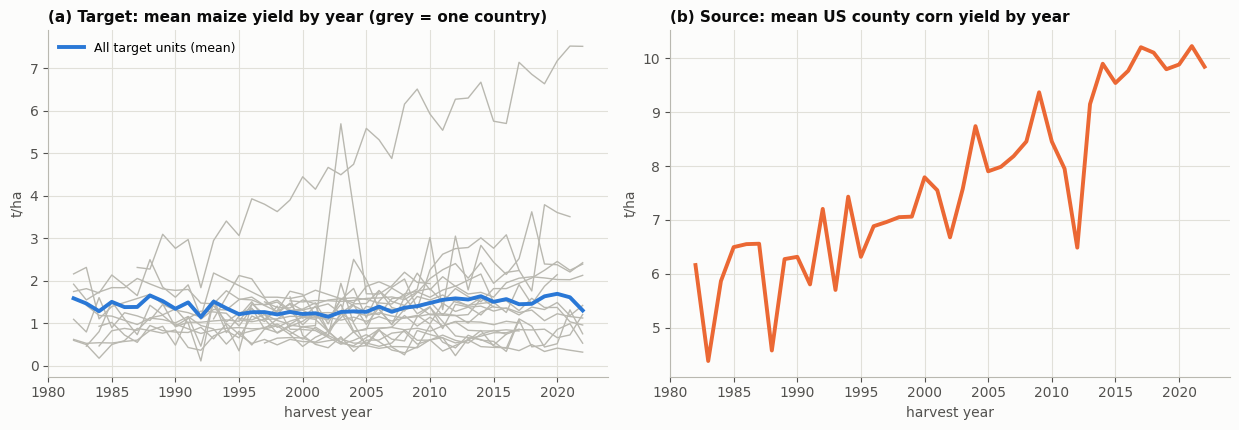

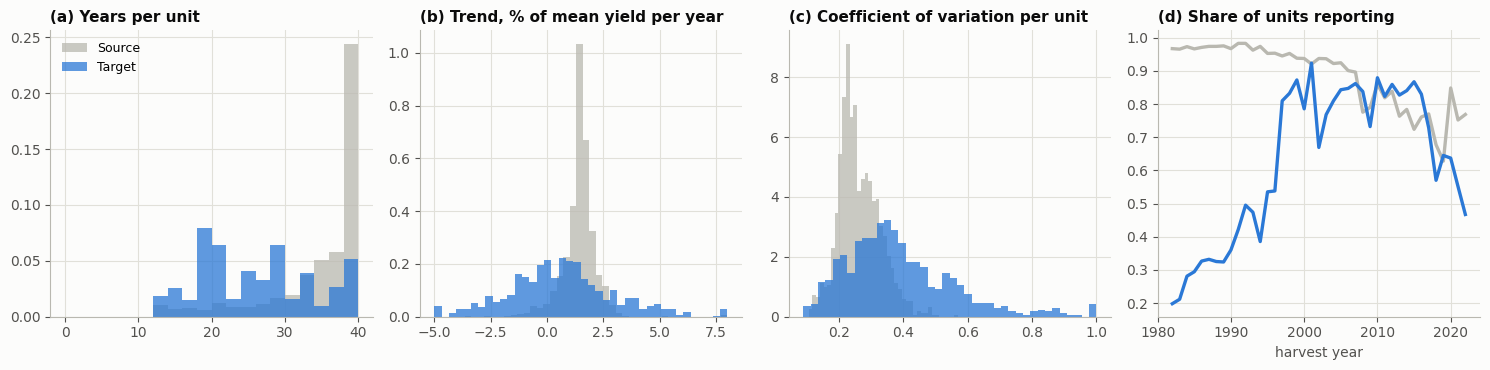

In [11]:
# EDA 1: yield levels over time
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
for c, g in tdf.groupby("country"):
    m = g.groupby("year").y.mean()
    ax[0].plot(m.index, m.values, color=GREY, lw=1)
pooled = tdf.groupby("year").y.mean()
ax[0].plot(pooled.index, pooled.values, color=BLUE, lw=2.8, label="All target units (mean)")
ax[0].set_title("(a) Target: mean maize yield by year (grey = one country)"); ax[0].set_ylabel("t/ha"); ax[0].legend()
sm = sdf.groupby("year").y.mean()
ax[1].plot(sm.index, sm.values, color=ORANGE, lw=2.8)
ax[1].set_title("(b) Source: mean US county corn yield by year"); ax[1].set_ylabel("t/ha")
for a in ax: a.set_xlabel("harvest year")
plt.tight_layout(); plt.show()

# EDA 2: record quality
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for df, col, lab in ((sdf, GREY, "Source"), (tdf, BLUE, "Target")):
    g = df.groupby("unit")
    ax[0].hist(g.size(), bins=np.arange(0, 42, 2), alpha=0.75, color=col, density=True, label=lab)
    slope = g.apply(lambda d: np.polyfit(d.year - d.year.mean(), d.y, 1)[0] / d.y.mean() * 100 if len(d) > 5 else np.nan)
    ax[1].hist(slope.dropna().clip(-5, 8), bins=40, alpha=0.75, color=col, density=True)
    cv = (g.y.std() / g.y.mean()).dropna()
    ax[2].hist(cv.clip(0, 1), bins=40, alpha=0.75, color=col, density=True)
    share = df.groupby("year").size() / df.unit.nunique()
    ax[3].plot(share.index, share.values, color=col, lw=2.4)
ax[0].set_title("(a) Years per unit"); ax[0].legend()
ax[1].set_title("(b) Trend, % of mean yield per year"); ax[2].set_title("(c) Coefficient of variation per unit")
ax[3].set_title("(d) Share of units reporting"); ax[3].set_xlabel("harvest year")
plt.tight_layout(); plt.show()

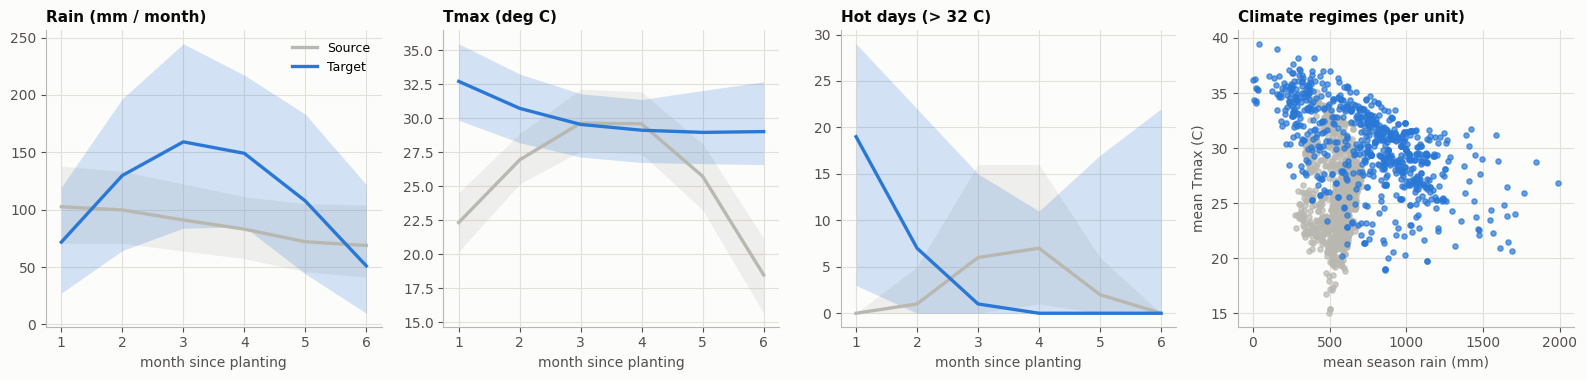

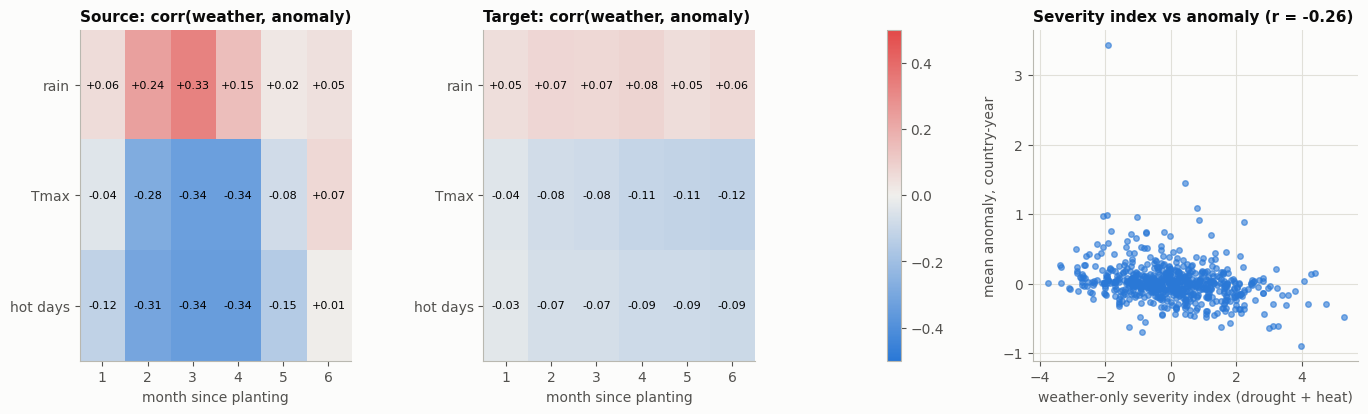

Check: severity index vs actual anomaly correlation = -0.26. A clearly negative value means the weather-only index does pick bad years.


In [12]:
# EDA 3: climate of the two regions, months counted from planting
fig, ax = plt.subplots(1, 4, figsize=(16, 3.9))
mon = np.arange(1, SEASON_MONTHS + 1)
for v, (a, nm) in enumerate(zip(ax[:3], ("Rain (mm / month)", "Tmax (deg C)", "Hot days (> %.0f C)" % cfg.hot_thr))):
    for p, col, lab in ((src, GREY, "Source"), (tgt, BLUE, "Target")):
        q = np.percentile(p.wx[:, :, v], [25, 50, 75], axis=0)
        a.plot(mon, q[1], color=col, lw=2.4, label=lab)
        a.fill_between(mon, q[0], q[2], color=col, alpha=0.2, linewidth=0)
    a.set_title(nm); a.set_xlabel("month since planting")
ax[0].legend()
for p, col, lab in ((src, GREY, "Source"), (tgt, BLUE, "Target")):
    ids, st = district_climatology(p)
    ax[3].scatter(st[:, 0], st[:, 1], s=14, color=col, alpha=0.7, label=lab)
ax[3].set_title("Climate regimes (per unit)"); ax[3].set_xlabel("mean season rain (mm)"); ax[3].set_ylabel("mean Tmax (C)")
plt.tight_layout(); plt.show()

# EDA 4: which weather variables relate to anomalies, and does the severity index work?
div = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", RED])
fig = plt.figure(figsize=(16.5, 4.3))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 0.05, 1.2], wspace=0.6)
ax = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[3])]
cax = fig.add_subplot(gs[2])
for a, p, df, lab in ((ax[0], src, sdf, "Source"), (ax[1], tgt, tdf, "Target")):
    Z, an = seq_features(p), df.anom.values
    cor = np.array([np.corrcoef(Z[:, j], an)[0, 1] for j in range(Z.shape[1])]).reshape(SEASON_MONTHS, 3).T
    im = a.imshow(cor, cmap=div, vmin=-0.5, vmax=0.5, aspect="auto")
    a.set_xticks(range(SEASON_MONTHS)); a.set_xticklabels(mon); a.set_yticks(range(3)); a.set_yticklabels(["rain", "Tmax", "hot days"])
    for i in range(3):
        for j in range(SEASON_MONTHS):
            a.text(j, i, f"{cor[i, j]:+.2f}", ha="center", va="center", fontsize=8)
    a.set_title(f"{lab}: corr(weather, anomaly)"); a.set_xlabel("month since planting"); a.grid(False)
fig.colorbar(im, cax=cax); cax.grid(False)
cy_all = country_year_severity(tgt)
mean_an = tdf.groupby(["cidx", "year"]).anom.mean().reset_index().rename(columns={"cidx": "country"})
cm = cy_all.merge(mean_an, on=["country", "year"])
ax[2].scatter(cm.sev, cm.anom, s=16, color=BLUE, alpha=0.6)
r = np.corrcoef(cm.sev, cm.anom)[0, 1]
ax[2].set_title(f"Severity index vs anomaly (r = {r:.2f})")
ax[2].set_xlabel("weather-only severity index (drought + heat)"); ax[2].set_ylabel("mean anomaly, country-year")
plt.show()
print(f"Check: severity index vs actual anomaly correlation = {r:.2f}. A clearly negative value means the weather-only index does pick bad years.")

## 4. Feature engineering and extreme-year labelling
What the model actually sees, and why:
1. The target is the anomaly, `yield / trend - 1`. That removes the gap between a 9 t/ha US county and a 1.5 t/ha African district, so one model can learn how yield *responds to weather* in both.
2. Each district gets its own linear trend, which takes out technology and management drift.
3. Weather is z-scored per district and per month (rain is log-transformed first), so the network sees "drier than usual for that place".
4. Four static climate descriptors (mean season rain, mean Tmax, rainfall seasonality, dry-month share) say what regime a district is in. Method B also uses them.
5. Months are counted from planting, so month 3 is roughly flowering on both continents whatever the calendar says.
6. Extreme years are picked per country, from weather alone. No yield leaks into the choice, and a drought in one country isn't averaged away by a good year in another.

In [13]:
ids_s, st_s_raw = district_climatology(src)
ids_t, st_t_raw = district_climatology(tgt)
Zs, Zt = seq_features(src), seq_features(tgt)
names = [f"{v}_m{k + 1}_z" for k in range(SEASON_MONTHS) for v in ("rain", "tmax", "hot")]
feat = pd.DataFrame(Zt, columns=names)
feat.insert(0, "country", tdf.country.values); feat.insert(1, "year", tdf.year.values); feat["anomaly"] = tdf.anom.values
display(feat.head(8))

cy, m_ext = pick_extreme_country_years(tgt, cfg)
ok_row = ~m_ext
year_pool = eligible_years(tgt, ok_row, cfg)
print(f"extreme country-years: {int(cy.extreme.sum())}  ({int(m_ext.sum())} rows)   normal years available for sampling: {len(year_pool)}")
ex = cy[cy.extreme].copy(); ex["country"] = [tgt.country_names[i] for i in ex.country]
display(ex.sort_values(["country", "year"]).head(25))

,country,year,rain_m1_z,tmax_m1_z,hot_m1_z,rain_m2_z,tmax_m2_z,hot_m2_z,rain_m3_z,tmax_m3_z,hot_m3_z,rain_m4_z,tmax_m4_z,hot_m4_z,rain_m5_z,tmax_m5_z,hot_m5_z,rain_m6_z,tmax_m6_z,hot_m6_z,anomaly
0,Angola,1997,-0.779,-0.278,-0.067,0.140,0.896,0.978,0.201,-0.307,-0.275,-0.356,-0.348,-0.306,0.730,-0.261,0.100,1.724,-2.038,-2.343,-0.212
1,Angola,1998,-0.930,1.391,0.641,-1.343,1.152,0.804,-1.406,0.732,0.687,1.839,-1.242,-1.271,-2.977,0.351,0.292,-1.725,0.717,0.758,-0.076
2,Angola,1999,-0.566,-0.616,0.641,1.158,-1.005,-0.414,-0.163,-0.186,0.046,0.998,-0.689,-0.628,0.595,-0.831,-0.283,-0.315,-0.264,0.195,0.215
3,Angola,2000,-1.331,-0.159,-0.776,-1.244,0.615,0.630,-0.551,0.293,0.526,0.049,0.473,0.659,0.557,-0.757,0.100,-0.468,0.374,0.758,0.659
4,Angola,2001,1.366,-1.738,-0.067,1.350,-1.013,-0.589,1.468,-1.357,-1.396,0.794,-1.863,-1.271,1.489,-3.055,-4.000,0.933,-2.199,-2.484,-0.151
5,Angola,2002,-1.553,0.718,-0.067,0.453,0.410,0.282,-1.423,0.871,1.007,-1.592,0.881,0.659,0.353,0.737,0.292,-1.086,-0.236,0.054,-0.057
6,Angola,2003,-0.295,-0.205,0.641,-1.514,0.646,0.978,-0.216,0.148,0.526,0.821,0.058,-0.628,0.425,-0.450,-0.091,0.121,0.005,0.477,-0.108
7,Angola,2004,-1.041,0.560,0.641,-0.115,0.076,0.282,-0.699,0.809,0.847,-0.139,0.119,0.015,0.313,0.417,0.483,0.305,0.352,0.618,0.144


extreme country-years: 117  (3485 rows)   normal years available for sampling: 41


,country,year,sev,n,extreme
7,Angola,2004,1.742,18,True
8,Angola,2005,1.468,18,True
9,Angola,2006,1.668,18,True
20,Angola,2017,2.121,18,True
63,Benin,1998,2.437,76,True
65,Benin,2000,2.518,76,True
79,Benin,2014,1.588,76,True
80,Benin,2015,2.686,76,True
81,Benin,2016,1.145,76,True
21,Burkina Faso,1984,1.814,31,True


## 5. Train / validation / calibration / test design
Splits are by **year**, never by random row, so no weather year leaks across sets.

| Set | Source or target | Used for |
|---|---|---|
| Pre-training | source (90%) | learn weather → anomaly response |
| Pre-training validation | source (10% random) | early stopping in pre-training |
| Fine-tune | target, a few normal years | adapt to the target (3, 5 or 8 years) |
| Validation | target, 3 normal years | early stopping during fine-tuning |
| Calibration | target, 5 normal years | calibrate conformal intervals |
| **Normal test** | target, remaining normal years | performance in ordinary years |
| **Extreme test** | target, extreme country-years | the real question: performance in droughts and heat |

Extreme country-years are removed from every set except the extreme test. The split is redrawn in each repetition.

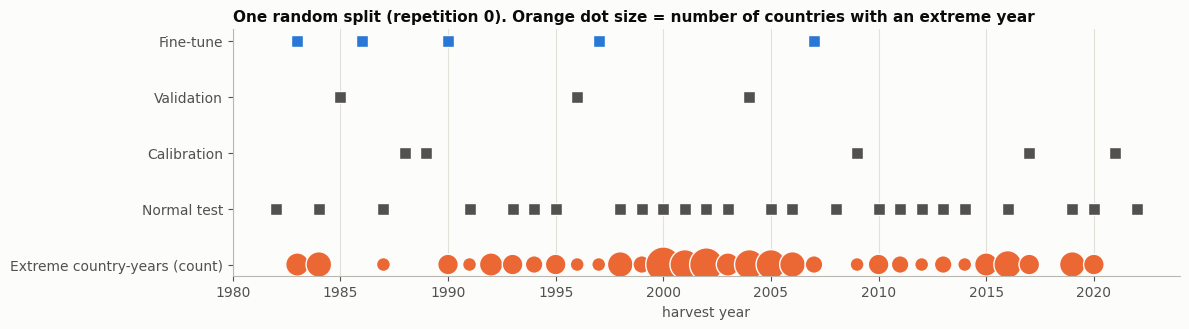

In [14]:
cal_y, val_y, pool_y, test_y = year_split(year_pool, cfg, np.random.default_rng(cfg.seed * 1000))
ft_y = pool_y[:cfg.main_ft]
years_all = np.arange(cfg.year0, cfg.year1 + 1)
rows = [("Extreme country-years (count)", None), ("Normal test", test_y), ("Calibration", cal_y),
        ("Validation", val_y), ("Fine-tune", ft_y)]
fig, ax = plt.subplots(figsize=(12, 3.4))
ncty = cy[cy.extreme].groupby("year").size().reindex(years_all).fillna(0)
for i, (lab, yrs) in enumerate(rows):
    if yrs is None:
        ax.scatter(years_all[ncty.values > 0], np.full((ncty.values > 0).sum(), i), s=40 + 60 * ncty.values[ncty.values > 0],
                   color=ORANGE, edgecolor=SURFACE)
    else:
        ax.scatter(yrs, np.full(len(yrs), i), s=70, marker="s", color=BLUE if lab == "Fine-tune" else INK2, edgecolor=SURFACE)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows]); ax.set_xlabel("harvest year")
ax.set_title("One random split (repetition 0). Orange dot size = number of countries with an extreme year", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 6. Models and techniques
| Name | What it is | Why it is here |
|---|---|---|
| **Trend only** | predicts anomaly 0 | the floor: what you get from the trend alone |
| **Ridge (local)** | linear model trained on the few target years | simple, strong when data are scarce |
| **Gradient boosting (local)** | histogram gradient-boosted trees | strong tabular baseline |
| **MLP (local)** | small neural net trained on target years only | shows the cost of no transfer |
| **Zero-shot transfer** | MLP pre-trained on US corn, no target data | how far the source alone gets |
| **Standard fine-tune** | zero-shot + fine-tuning on target years | the transfer baseline to beat |
| **A: stress-weighted** | Huber loss where severe anomalies, shortfalls most, get more weight | tests whether emphasising extremes helps |
| **B: regime-matched** | source counties weighted by climate similarity to the target | tests whether matching climate regimes helps |
| **A + B (proposed)** | both together | the project's method |
| **Direct classifier** | gradient boosting predicting "shortfall yes/no" | classification baseline |
| **Conformal intervals (D)** | split conformal, plain vs covariate-shift weighted (Tibshirani et al. 2019) | calibrated uncertainty, checked in extreme years |
| **Transformer (optional)** | attention over the six monthly tokens | tested only if PyTorch is installed |

Supporting techniques: Adam optimiser with cosine learning-rate decay, **L2-SP** regularisation (fine-tuned weights stay close to the pre-trained ones),
early stopping on a validation set, paired bootstrap confidence intervals over repetitions, and a sensitivity sweep over the strength of method A.
**No hyper-parameter is tuned on the extreme test years.**

In [15]:
def stress_weights(z, lam, gamma, clip_c, kappa):
    """Method A: loss weights from standardised anomalies z.

        w = 1 + lam * min(|z|, c)^gamma * (kappa if z < 0 else 1)

    Ordinary years stay near 1, severe anomalies (shortfalls most of all) count more.
    Weights are rescaled to mean 1 so the learning rate keeps its usual meaning."""
    base = np.minimum(np.abs(z), clip_c) ** gamma
    w = 1.0 + lam * base * np.where(z < 0, kappa, 1.0)
    return w / w.mean()


def regime_weights(static_src, static_tgt, k, tau_scale, w_clip):
    """Method B: one weight per source district, based on how similar its climate is to the target.

        d = mean distance to the k nearest target districts (static climate space)
        v = exp(-d / tau),   tau = tau_scale * median(d)

    Similarity uses long-term climate, not single seasons, so a drought year in a
    matching region is kept rather than filtered out."""
    dk = np.sort(cdist(static_src, static_tgt), axis=1)[:, :k].mean(1)
    v = np.exp(-dk / (tau_scale * np.median(dk) + 1e-9))
    v = np.minimum(v / v.mean(), w_clip)
    return v / v.mean()


class MLP:
    """A plain fully connected network (ReLU hidden layers, linear output) with hand-written backprop."""

    def __init__(self, sizes, rng):
        self.W = [rng.normal(0, math.sqrt(2.0 / sizes[i]), (sizes[i], sizes[i + 1]))
                  for i in range(len(sizes) - 1)]
        self.b = [np.zeros(sizes[i + 1]) for i in range(len(sizes) - 1)]

    def forward(self, X):
        acts, h = [X], X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = h @ W + b
            h = z if i == len(self.W) - 1 else np.maximum(z, 0.0)
            acts.append(h)
        return h[:, 0], acts

    def backward(self, acts, dout):
        gW, gb, delta = [], [], dout[:, None]
        for i in reversed(range(len(self.W))):
            gW.insert(0, acts[i].T @ delta)
            gb.insert(0, delta.sum(0))
            if i > 0:
                delta = (delta @ self.W[i].T) * (acts[i] > 0)
        return gW, gb

    def params(self):
        return self.W + self.b

    def copy(self):
        m = MLP.__new__(MLP)
        m.W, m.b = [w.copy() for w in self.W], [b.copy() for b in self.b]
        return m

    def predict(self, X):
        return self.forward(X)[0]


def train_mlp(model, X, y, w, epochs, lr, batch, wd, rng, delta=1.0, ref=None,
              l2sp=0.0, val=None, patience=8, hist=None):
    """Weighted Huber loss, Adam, cosine learning rate.

    Optionally pulls the weights toward `ref` (L2-SP, used when fine-tuning), stops early
    on `val`, and records the validation loss per epoch in `hist`."""
    params = model.params()
    nW = len(model.W)
    m1 = [np.zeros_like(p) for p in params]
    m2 = [np.zeros_like(p) for p in params]
    n, t = len(y), 0
    best, best_loss, bad = None, np.inf, 0
    for ep in range(epochs):
        lr_e = lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * ep / max(epochs, 1))))
        idx = rng.permutation(n)
        for s in range(0, n, batch):
            b = idx[s:s + batch]
            pred, acts = model.forward(X[b])
            g = np.clip(pred - y[b], -delta, delta) * w[b] / (w[b].sum() + 1e-12)
            gW, gb = model.backward(acts, g)
            t += 1
            for k, (p, gr) in enumerate(zip(params, gW + gb)):
                if k < nW:
                    gr = gr + wd * p
                if ref is not None:
                    gr = gr + l2sp * (p - ref[k])
                m1[k] = 0.9 * m1[k] + 0.1 * gr
                m2[k] = 0.999 * m2[k] + 0.001 * gr * gr
                p -= lr_e * (m1[k] / (1 - 0.9 ** t)) / (np.sqrt(m2[k] / (1 - 0.999 ** t)) + 1e-8)
        if val is not None:
            vl = float(np.mean((model.predict(val[0]) - val[1]) ** 2))
            if hist is not None:
                hist.append(vl)
            if vl < best_loss - 1e-5:
                best_loss, best, bad = vl, model.copy(), 0
            else:
                bad += 1
                if bad >= patience:
                    break
    if best is not None:
        model.W, model.b = best.W, best.b
    return model


def _prf(pos, pp):
    """Precision, recall and F1 for boolean predictions pp against boolean truth pos."""
    tp, fn, fp = (pos & pp).sum(), (pos & ~pp).sum(), (~pos & pp).sum()
    rec = tp / (tp + fn) if tp + fn else np.nan
    prec = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) and np.isfinite(prec + rec) else np.nan
    return prec, rec, f1


def _rank_scores(pos, score):
    """ROC-AUC and average precision; NaN if only one class is present."""
    if pos.any() and (~pos).any():
        return float(roc_auc_score(pos, score)), float(average_precision_score(pos, score))
    return np.nan, np.nan


def metrics(a_true, a_pred, trend, thr):
    """Regression errors (anomaly x100 = percentage points, and t/ha) plus shortfall classification scores.

    A shortfall is an anomaly below thr. The ranking score is minus the predicted anomaly;
    the hard label is predicted anomaly < thr."""
    e = a_pred - a_true
    ss_tot = ((a_true - a_true.mean()) ** 2).sum()
    pos, pp = a_true < thr, a_pred < thr
    prec, rec, f1 = _prf(pos, pp)
    auc, ap = _rank_scores(pos, -a_pred)
    return dict(rmse_pp=100 * math.sqrt(np.mean(e ** 2)), mae_pp=100 * np.mean(np.abs(e)),
                bias_pp=100 * np.mean(e), r2=1 - (e ** 2).sum() / ss_tot if ss_tot > 0 else np.nan,
                rmse_t=math.sqrt(np.mean((trend * e) ** 2)), recall=rec, prec=prec, f1=f1,
                auc=auc, ap=ap, n=len(e))


def clf_metrics(a_true, proba, thr):
    """Same keys as metrics() for a direct shortfall classifier (regression fields left as NaN)."""
    pos = a_true < thr
    prec, rec, f1 = _prf(pos, proba > 0.5)
    auc, ap = _rank_scores(pos, proba)
    nan = np.nan
    return dict(rmse_pp=nan, mae_pp=nan, bias_pp=nan, r2=nan, rmse_t=nan, recall=rec, prec=prec,
                f1=f1, auc=auc, ap=ap, n=len(pos))


def conformal_halfwidths(scores, w_cal, w_test, alpha):
    """Split-conformal half-widths with optional covariate-shift weights (Tibshirani et al. 2019).

    scores: absolute calibration residuals; w_cal: their weights; w_test: weight of each
    test point. With all weights equal to 1 this is ordinary split conformal.
    Returns (half-width per test point, share of points whose interval is unbounded)."""
    o = np.argsort(scores)
    s, cum = scores[o], np.cumsum(w_cal[o])
    thresh = (1 - alpha) * (cum[-1] + w_test)
    k = np.searchsorted(cum, thresh, side="left")
    unbounded = k >= len(s)
    hw = s[np.minimum(k, len(s) - 1)].copy()
    hw[unbounded] = 1.5 * s.max()  # cap it, and report the unbounded share separately
    return hw, float(unbounded.mean())


def density_ratio_weights(F_cal, F_test, clip=10.0):
    """Estimate p_test(x) / p_cal(x) with a regularised logistic regression on weather summaries.

    Strong regularisation (C=0.1) and a clip stop the weights exploding when calibration and
    test weather barely overlap, which is exactly the situation in extreme years. When the
    two sets are close to separable the intervals honestly become very wide."""
    X = np.vstack([F_cal, F_test])
    lab = np.r_[np.zeros(len(F_cal)), np.ones(len(F_test))]
    clf = LogisticRegression(C=0.1, max_iter=500).fit(X, lab)

    def ratio(F):
        p = np.clip(clf.predict_proba(F)[:, 1], 1e-4, 1 - 1e-4)
        return np.clip(p / (1 - p) * (len(F_cal) / len(F_test)), 1e-3, clip)
    return ratio(F_cal), ratio(F_test)


METHODS = [  # (key, label, is_proposed)
    ("trend", "Trend only", False),
    ("ridge", "Ridge (local)", False),
    ("gbm", "Gradient boosting (local)", False),
    ("mlp_local", "MLP (local, no transfer)", False),
    ("zero", "Zero-shot transfer", False),
    ("std", "Standard fine-tune", False),
    ("A", "A: stress-weighted", False),
    ("B", "B: regime-matched", False),
    ("AB", "A + B (proposed)", True),
]


LABEL = {k: l for k, l, _ in METHODS}


def tic():
    return time.time()


def run_experiment(cfg: Cfg, src: Panel, tgt: Panel, log=print):
    """Run every repetition and return the result tables plus what the figures need."""
    t0 = tic()

    # features
    ids_s, st_s = district_climatology(src)
    ids_t, st_t = district_climatology(tgt)
    pool = np.vstack([st_s, st_t])
    mu, sd = pool.mean(0), pool.std(0) + 1e-9
    st_s, st_t = (st_s - mu) / sd, (st_t - mu) / sd           # standardise with pooled stats
    map_s = {d: st_s[i] for i, d in enumerate(ids_s)}
    map_t = {d: st_t[i] for i, d in enumerate(ids_t)}
    Zs, Zt = seq_features(src), seq_features(tgt)
    if cfg.use_static:
        Xs = np.hstack([Zs, np.stack([map_s[d] for d in src.dist])])
        Xt = np.hstack([Zt, np.stack([map_t[d] for d in tgt.dist])])
    else:
        Xs, Xt = Zs, Zt
    Fs_t = shift_features(Zt)

    # anomalies (the thing we actually predict)
    a_s, _ = detrend(src)
    sigma_ref = float(a_s.std())              # one shared scale so source and target are comparable
    z_s = a_s / sigma_ref
    a_t_full, tr_t_full = detrend(tgt)

    # extreme country-years, chosen from weather only
    cy, m_ext = pick_extreme_country_years(tgt, cfg)
    ok_row = ~m_ext                                        # rows that may be used for fine-tune / val / cal / normal test
    n_ext_cy = int(cy.extreme.sum())
    if n_ext_cy == 0 or m_ext.sum() < 30:
        sys.exit("Too few extreme target rows. Lower --min-country-years or add countries.")
    year_pool = eligible_years(tgt, ok_row, cfg)
    need = cfg.n_cal_years + cfg.n_val_years + max(cfg.ft_sizes) + 3
    if len(year_pool) < need:
        sys.exit(f"Only {len(year_pool)} usable normal years; need {need}. Lower --min-rows-year.")
    log(f"  target: {len(tgt.y)} rows | extreme country-years: {n_ext_cy} "
        f"({int(m_ext.sum())} rows held out) | normal years available: {len(year_pool)}")

    # method B weights: source district -> one weight per sample
    wB_dist = regime_weights(st_s, st_t, cfg.k_nn, cfg.tau_scale, cfg.w_clip)
    wB_map = {d: wB_dist[i] for i, d in enumerate(ids_s)}
    wB = np.array([wB_map[d] for d in src.dist])
    wA_s = stress_weights(z_s, cfg.lam, cfg.gamma, cfg.clip_c, cfg.kappa)
    wAB = wA_s * wB
    wAB = wAB / wAB.mean()
    pre_weights = {"std": np.ones(len(z_s)), "A": wA_s, "B": wB, "AB": wAB}

    split_masks = lambda rng: year_split(year_pool, cfg, rng)

    # main loop over repetitions
    records, conf_records, preds_keep = [], [], {}
    curves = dict(pre={}, ft={})
    split0 = {}
    maxft = max(cfg.ft_sizes)
    for rep in range(cfg.n_reps):
        rng = np.random.default_rng(cfg.seed * 1000 + rep)
        cal_years, val_years, rest, norm_test_years = split_masks(rng)
        # pretrain the four variants; same init seed within a rep so comparisons are paired
        val_idx = rng.choice(len(z_s), size=len(z_s) // 10, replace=False)
        tr_idx = np.setdiff1d(np.arange(len(z_s)), val_idx)
        init_seed = int(rng.integers(1e9))
        pre = {}
        for key, w in pre_weights.items():
            net = MLP([Xs.shape[1], *cfg.hidden, 1], np.random.default_rng(init_seed))
            h = []
            pre[key] = train_mlp(net, Xs[tr_idx], z_s[tr_idx], w[tr_idx], cfg.pre_epochs,
                                 cfg.pre_lr, cfg.batch, cfg.weight_decay,
                                 np.random.default_rng(init_seed + 1), cfg.huber_delta,
                                 val=(Xs[val_idx], z_s[val_idx]), hist=h)
            if rep == 0:
                curves["pre"][key] = h
        m_nrm = np.isin(tgt.year, norm_test_years) & ok_row
        m_val = np.isin(tgt.year, val_years) & ok_row
        m_cal = np.isin(tgt.year, cal_years) & ok_row
        for n_ft in cfg.ft_sizes:
            ft_years = rest[:n_ft]
            m_ft = np.isin(tgt.year, ft_years) & ok_row
            if cfg.detrend == "train":
                a_t, tr_t = detrend(tgt, fit_mask=m_ft)
            else:
                a_t, tr_t = a_t_full, tr_t_full
            Xf, zf = Xt[m_ft], a_t[m_ft] / sigma_ref
            wA_f = stress_weights(zf, cfg.lam, cfg.gamma, cfg.clip_c, cfg.kappa)
            ft_seed = init_seed + 7 + n_ft

            Xv, zv = Xt[m_val], a_t[m_val] / sigma_ref

            def finetune(key, w):
                net = pre[key].copy()
                ref = [p.copy() for p in net.params()]
                h = []
                out = train_mlp(net, Xf, zf, w, cfg.ft_epochs, cfg.ft_lr, cfg.batch,
                                cfg.weight_decay, np.random.default_rng(ft_seed),
                                cfg.huber_delta, ref=ref, l2sp=cfg.l2sp, val=(Xv, zv), hist=h)
                if rep == 0 and n_ft == cfg.main_ft:
                    curves["ft"][key] = h
                return out

            nets = {"zero": pre["std"],
                    "std": finetune("std", np.ones(len(zf))),
                    "A": finetune("A", wA_f),
                    "B": finetune("B", np.ones(len(zf))),
                    "AB": finetune("AB", wA_f)}
            local = train_mlp(MLP([Xt.shape[1], *cfg.hidden, 1], np.random.default_rng(ft_seed)),
                              Xf, zf, np.ones(len(zf)), 150, cfg.pre_lr, cfg.batch, 1e-3,
                              np.random.default_rng(ft_seed + 1), cfg.huber_delta, val=(Xv, zv))
            ridge = Ridge(alpha=10.0).fit(Xf, a_t[m_ft])
            gbm = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, max_depth=3,
                                                min_samples_leaf=10, l2_regularization=1.0,
                                                random_state=ft_seed).fit(Xf, a_t[m_ft])

            pos_ft = a_t[m_ft] < cfg.shortfall_thr
            clf = None
            if pos_ft.sum() >= 5 and (~pos_ft).sum() >= 5:       # a plain classifier for shortfall yes/no
                clf = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, max_depth=3,
                                                     min_samples_leaf=10, l2_regularization=1.0,
                                                     class_weight="balanced",
                                                     random_state=ft_seed).fit(Xf, pos_ft)

            def predict(key, X):
                if key == "trend":
                    return np.zeros(len(X))
                if key == "ridge":
                    return ridge.predict(X)
                if key == "gbm":
                    return gbm.predict(X)
                if key == "mlp_local":
                    return local.predict(X) * sigma_ref
                return nets[key].predict(X) * sigma_ref

            for split, m in (("extreme", m_ext), ("normal", m_nrm)):
                for key, _, _ in METHODS:
                    r = metrics(a_t[m], predict(key, Xt[m]), tr_t[m], cfg.shortfall_thr)
                    records.append(dict(rep=rep, n_ft=n_ft, method=key, split=split, **r))
                if clf is not None:
                    r = clf_metrics(a_t[m], clf.predict_proba(Xt[m])[:, 1], cfg.shortfall_thr)
                    records.append(dict(rep=rep, n_ft=n_ft, method="clf_gbm", split=split, **r))
            if rep == 0 and n_ft == cfg.main_ft:
                split0 = dict(m_ft=m_ft, m_val=m_val, m_cal=m_cal, m_nrm=m_nrm, m_ext=m_ext, a_t=a_t,
                              tr_idx=tr_idx, val_idx=val_idx, wA_f=wA_f, years=dict(
                                  ft=[int(y) for y in rest[:n_ft]], val=[int(y) for y in val_years],
                                  cal=[int(y) for y in cal_years], test=[int(y) for y in norm_test_years]))
            if rep == 0 and n_ft == cfg.main_ft:
                preds_keep = {"true": a_t[m_ext], "year": tgt.year[m_ext],
                              "std": predict("std", Xt[m_ext]), "AB": predict("AB", Xt[m_ext]),
                              "A": predict("A", Xt[m_ext]), "B": predict("B", Xt[m_ext])}
            # method D: conformal intervals, headline fine-tune size only
            if n_ft == cfg.main_ft:
                w_cal_dr, w_ext_dr = density_ratio_weights(Fs_t[m_cal], Fs_t[m_ext])
                for key in ("std", "AB"):
                    sc = np.abs(a_t[m_cal] - predict(key, Xt[m_cal]))
                    p_ext, p_nrm = predict(key, Xt[m_ext]), predict(key, Xt[m_nrm])
                    for alpha in (0.2, 0.1):
                        hw_n, _ = conformal_halfwidths(sc, np.ones(len(sc)), np.ones(m_nrm.sum()), alpha)
                        hw_e, _ = conformal_halfwidths(sc, np.ones(len(sc)), np.ones(m_ext.sum()), alpha)
                        hw_w, unb = conformal_halfwidths(sc, w_cal_dr, w_ext_dr, alpha)
                        for kind, split, hw, yt, yp in (
                                ("plain", "normal", hw_n, a_t[m_nrm], p_nrm),
                                ("plain", "extreme", hw_e, a_t[m_ext], p_ext),
                                ("weighted", "extreme", hw_w, a_t[m_ext], p_ext)):
                            conf_records.append(dict(
                                rep=rep, model=key, alpha=alpha, kind=kind, split=split,
                                coverage=float(np.mean(np.abs(yt - yp) <= hw)),
                                width_pp=200 * float(hw.mean()),
                                unbounded=unb if kind == "weighted" else 0.0))
        if (rep + 1) % max(1, cfg.n_reps // 5) == 0 or rep == cfg.n_reps - 1:
            log(f"  rep {rep + 1}/{cfg.n_reps} done ({tic() - t0:.0f}s)")

    res = pd.DataFrame(records)
    conf = pd.DataFrame(conf_records)

    # sensitivity sweep over lambda (method A on its own)
    sweep = []
    for rep in range(cfg.sweep_reps):
        rng = np.random.default_rng(cfg.seed * 1000 + 500 + rep)
        cal_years, val_years, rest, norm_test_years = split_masks(rng)
        m_ft = np.isin(tgt.year, rest[:cfg.main_ft]) & ok_row
        m_nrm = np.isin(tgt.year, norm_test_years) & ok_row
        a_t, tr_t = (detrend(tgt, fit_mask=m_ft) if cfg.detrend == "train"
                     else (a_t_full, tr_t_full))
        Xf, zf = Xt[m_ft], a_t[m_ft] / sigma_ref
        init_seed = int(rng.integers(1e9))
        val_idx = rng.choice(len(z_s), size=len(z_s) // 10, replace=False)
        tr_idx = np.setdiff1d(np.arange(len(z_s)), val_idx)
        for lam in cfg.sweep_lams:
            w_pre = stress_weights(z_s, lam, cfg.gamma, cfg.clip_c, cfg.kappa)
            w_ft = stress_weights(zf, lam, cfg.gamma, cfg.clip_c, cfg.kappa)
            net = MLP([Xs.shape[1], *cfg.hidden, 1], np.random.default_rng(init_seed))
            net = train_mlp(net, Xs[tr_idx], z_s[tr_idx], w_pre[tr_idx], cfg.pre_epochs,
                            cfg.pre_lr, cfg.batch, cfg.weight_decay,
                            np.random.default_rng(init_seed + 1), cfg.huber_delta,
                            val=(Xs[val_idx], z_s[val_idx]))
            ref = [p.copy() for p in net.params()]
            net = train_mlp(net, Xf, zf, w_ft, cfg.ft_epochs, cfg.ft_lr, cfg.batch,
                            cfg.weight_decay, np.random.default_rng(init_seed + 9),
                            cfg.huber_delta, ref=ref, l2sp=cfg.l2sp)
            for split, m in (("extreme", m_ext), ("normal", m_nrm)):
                r = metrics(a_t[m], net.predict(Xt[m]) * sigma_ref, tr_t[m], cfg.shortfall_thr)
                sweep.append(dict(rep=rep, lam=lam, split=split, **r))
    sweep = pd.DataFrame(sweep)
    log(f"  sensitivity sweep done ({tic() - t0:.0f}s total)")

    # per-country numbers are computed later from the rep-0 predictions kept here
    payload = dict(
        cy=cy, n_ext_cy=n_ext_cy, country_names=tgt.country_names,
        a_src=a_s, a_tgt=a_t_full, tgt_year=tgt.year, tgt_ext=m_ext,
        st_s=st_s, st_t=st_t, wB_dist=wB_dist, sigma_ref=sigma_ref, preds=preds_keep,
        n_src_districts=len(ids_s), n_tgt_districts=len(ids_t),
        n_src_rows=len(src.y), n_tgt_rows=len(tgt.y), curves=curves, split0=split0,
        Xs=Xs, Xt=Xt, z_s=z_s, wA_s=wA_s, wB=wB, wAB=wAB)
    return res, conf, sweep, payload

## 7. Run the experiment
This is the long step (full run: roughly 15–30 minutes on a laptop CPU). Progress is printed every few repetitions.

In [16]:
t0 = tic()
res, conf, sweep, payload = run_experiment(cfg, src, tgt, log=log)
res.to_csv(os.path.join(cfg.out, "results.csv"), index=False)
conf.to_csv(os.path.join(cfg.out, "conformal.csv"), index=False)
sweep.to_csv(os.path.join(cfg.out, "sweep.csv"), index=False)
print(f"experiment finished in {(tic() - t0) / 60:.1f} min; {len(res)} result rows")

  target: 19143 rows | extreme country-years: 117 (3485 rows held out) | normal years available: 41
  rep 4/20 done (145s)
  rep 8/20 done (289s)
  rep 12/20 done (434s)
  rep 16/20 done (584s)
  rep 20/20 done (730s)
  sensitivity sweep done (966s total)
experiment finished in 16.1 min; 1200 result rows


## 8. Progress, evaluation and conclusions on the data

In [17]:
def boot_ci(x, n=3000, seed=0):
    """Mean and 95% bootstrap interval over repetitions."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    r = np.random.default_rng(seed)
    means = r.choice(x, size=(n, len(x)), replace=True).mean(1)
    return float(x.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


def summary_table(res, n_ft, split):
    """Mean and 95% CI per method, for one fine-tune size and one split."""
    rows = []
    d = res[(res.n_ft == n_ft) & (res.split == split)]
    for key, label, _ in METHODS:
        g = d[d.method == key]
        row = dict(method=label)
        for col, name in (("rmse_pp", "RMSE (pp)"), ("rmse_t", "RMSE (t/ha)"),
                          ("bias_pp", "Bias (pp)"), ("recall", "Shortfall recall")):
            m, lo, hi = boot_ci(g[col].values)
            row[name], row[name + " lo"], row[name + " hi"] = m, lo, hi
        rows.append(row)
    return pd.DataFrame(rows)


def paired_diffs(res, n_ft, split, base="std", col="rmse_pp"):
    """Per-repetition paired difference (method minus base). Negative means better than base."""
    d = res[(res.n_ft == n_ft) & (res.split == split)].pivot(index="rep", columns="method", values=col)
    out = []
    for key, label, _ in METHODS:
        if key == base:
            continue
        diff = (d[key] - d[base]).values
        m, lo, hi = boot_ci(diff, seed=1)
        out.append(dict(method=label, key=key, diff=m, lo=lo, hi=hi,
                        wins=int((diff < 0).sum()), reps=len(diff)))
    return pd.DataFrame(out)


CLS_METHODS = [("ridge", "Ridge (local)"), ("gbm", "Gradient boosting (local)"),
               ("mlp_local", "MLP (local)"), ("clf_gbm", "Direct classifier (GBM, local)"),
               ("zero", "Zero-shot transfer"), ("std", "Standard fine-tune"),
               ("A", "A: stress-weighted"), ("B", "B: regime-matched"), ("AB", "A + B (proposed)")]


def class_table(res, n_ft, split):
    """Shortfall classification scores averaged over repetitions, for one split."""
    d = res[(res.n_ft == n_ft) & (res.split == split)]
    rows = []
    for key, label in CLS_METHODS:
        g = d[d.method == key]
        if len(g):
            rows.append(dict(method=label, **{c: g[c].mean() for c in ("auc", "ap", "recall", "prec", "f1")}))
    return pd.DataFrame(rows).rename(columns={"auc": "ROC-AUC", "ap": "Avg precision", "recall": "Recall",
                                              "prec": "Precision", "f1": "F1"})


def b64(path):
    with open(path, "rb") as f:
        return base64.b64encode(f.read()).decode()


def findings_text(res, conf, cfg):
    """Plain-language findings written from the numbers, hedged by the confidence intervals."""
    out = []
    n = cfg.main_ft
    for split in ("extreme", "normal"):
        d = paired_diffs(res, n, split).set_index("key")
        for key in ("A", "B", "AB"):
            r = d.loc[key]
            if r["hi"] < 0:
                verdict = "a reliable improvement"
            elif r["lo"] > 0:
                verdict = "a reliable deterioration"
            else:
                verdict = "no reliable difference (the interval includes zero)"
            out.append(f"{LABEL[key]} vs standard fine-tune, {split} years: {r['diff']:+.2f} pp RMSE "
                       f"[{r['lo']:+.2f}, {r['hi']:+.2f}], better in {r['wins']}/{r['reps']} repetitions - {verdict}.")
    cd = conf[(conf.model == "AB") & (conf.alpha == 0.1)]
    cov = {(k, s): cd[(cd.kind == k) & (cd.split == s)].coverage.mean()
           for k, s in (("plain", "normal"), ("plain", "extreme"), ("weighted", "extreme"))}
    out.append(f"90% intervals (A+B): coverage {cov[('plain', 'normal')]:.0%} in normal years with plain conformal; "
               f"{cov[('plain', 'extreme')]:.0%} in extreme years with plain conformal; "
               f"{cov[('weighted', 'extreme')]:.0%} in extreme years with shift-weighted conformal.")
    return out


def fig_overview(payload, cfg, path):
    """Four panels: anomaly distributions, climate regimes, the loss weights, and the extreme years."""
    seq = LinearSegmentedColormap.from_list("seq", SEQ_BLUE)
    fig, ax = plt.subplots(2, 2, figsize=(11.5, 8.2))
    fig.suptitle("The setup: what the data look like and what methods A and B do",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    # (a) anomaly distributions
    a = ax[0, 0]
    bins = np.linspace(-0.7, 0.5, 49)
    a.hist(payload["a_src"], bins=bins, density=True, color=GREY, alpha=0.85, label="Source")
    a.hist(payload["a_tgt"], bins=bins, density=True, color=BLUE, alpha=0.65, label="Target")
    a.axvspan(-0.7, cfg.shortfall_thr, color=ORANGE, alpha=0.12)
    a.text(cfg.shortfall_thr - 0.015, a.get_ylim()[1] * 0.9, "shortfall zone", ha="right",
           color=ORANGE, fontsize=9, fontweight="bold")
    a.set_title("(a) Yield anomalies: the left tail is rare")
    a.set_xlabel("relative anomaly (yield / trend - 1)")
    a.set_ylabel("density")
    a.legend(loc="upper left")
    # (b) regime space
    b = ax[0, 1]
    pca = PCA(2).fit(np.vstack([payload["st_s"], payload["st_t"]]))
    ps, pt = pca.transform(payload["st_s"]), pca.transform(payload["st_t"])
    sc = b.scatter(ps[:, 0], ps[:, 1], c=payload["wB_dist"], cmap=seq, s=26, edgecolor=SURFACE,
                   linewidth=0.5)
    b.scatter(pt[:, 0], pt[:, 1], marker="D", s=34, color=ORANGE, edgecolor=SURFACE,
              linewidth=0.8, label="Target districts")
    cb = fig.colorbar(sc, ax=b, fraction=0.046, pad=0.02)
    cb.set_label("method B weight (source)")
    b.set_title("(b) B: source districts near the target get more weight")
    b.set_xlabel("climate regime, axis 1")
    b.set_ylabel("climate regime, axis 2")
    b.legend(loc="best")
    # (c) A weight curve
    c = ax[1, 0]
    z = np.linspace(-4, 4, 400)
    for lam, col in ((0.5, AQUA), (cfg.lam, BLUE), (4.0, VIOLET)):
        w = 1 + lam * np.minimum(np.abs(z), cfg.clip_c) ** cfg.gamma * np.where(z < 0, cfg.kappa, 1.0)
        c.plot(z, w, color=col, lw=2.2, label=f"lambda = {lam:g}" + ("  (default)" if lam == cfg.lam else ""))
    c.axvline(0, color=GREY, lw=1)
    c.set_title("(c) A: severe anomalies, shortfalls most, count more")
    c.set_xlabel("standardised anomaly z  (negative = below trend)")
    c.set_ylabel("loss weight before rescaling")
    c.legend(loc="upper center")
    # (d) extreme country-years
    d = ax[1, 1]
    cy = payload["cy"]
    nrm, ex = cy[~cy.extreme], cy[cy.extreme]
    d.scatter(nrm.year, nrm.sev, s=14, color=GREY, alpha=0.7, label="Normal country-year")
    d.scatter(ex.year, ex.sev, s=26, color=ORANGE, edgecolor=SURFACE, linewidth=0.5,
              label="Held out as extreme")
    d.set_title("(d) Extreme years are picked from weather, per country")
    d.set_xlabel("harvest year")
    d.set_ylabel("weather severity (drought + heat)")
    d.set_ylim(top=cy.sev.max() + 0.9)
    d.legend(loc="upper left", ncol=2, fontsize=8)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return _save(fig, path)


def fig_main(res, cfg, path):
    """Headline comparison: extreme-year RMSE, normal-year RMSE, shortfall recall."""
    n = cfg.main_ft
    ext, nrm = summary_table(res, n, "extreme"), summary_table(res, n, "normal")
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.9), sharey=True)
    fig.suptitle(f"Headline result: {n} labelled target years, extreme years held out",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    order = list(range(len(METHODS)))[::-1]
    labels = [METHODS[i][1] for i in order]
    for a, df, col, title, lower in ((ax[0], ext, "RMSE (pp)", "Extreme years: RMSE (pp)", True),
                                     (ax[1], nrm, "RMSE (pp)", "Normal years: RMSE (pp)", True),
                                     (ax[2], ext, "Shortfall recall", "Extreme years: shortfall recall", False)):
        for yi, i in enumerate(order):
            r = df.iloc[i]
            col_pt = BLUE if METHODS[i][2] else (INK2 if METHODS[i][0] == "std" else GREY)
            a.plot([r[col + " lo"], r[col + " hi"]], [yi, yi], color=col_pt, lw=2.2, solid_capstyle="round")
            a.plot(r[col], yi, "o", color=col_pt, ms=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
            a.text(r[col + " hi"], yi, f"  {r[col]:.1f}" if lower else f"  {r[col]:.2f}", va="center",
                   fontsize=8.5, color=INK2)
        a.set_yticks(range(len(order)))
        a.set_yticklabels(labels)
        a.set_title(title)
        a.set_xlabel("lower is better" if lower else "higher is better")
        a.grid(axis="y", visible=False)
        for tl in a.get_yticklabels():
            if "proposed" in tl.get_text():
                tl.set_fontweight("bold")
                tl.set_color(BLUE)
    fig.text(0.01, -0.02, "Dots = mean over repetitions, bars = 95% bootstrap CI. Proposed method in blue, "
             "standard fine-tune in dark grey.", fontsize=8.5, color=MUTED)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return _save(fig, path)


def fig_scarcity(res, cfg, path):
    """Extreme-year RMSE as the number of labelled target years grows."""
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
    fig.suptitle("How much target data does each approach need?",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    series = (("std", "Standard fine-tune", INK2, "-"), ("A", "A", AQUA, "-"),
              ("B", "B", ORANGE, "-"), ("AB", "A + B", BLUE, "-"), ("gbm", "GBM (local)", GREY, "--"))
    for a, split in zip(ax, ("extreme", "normal")):
        for key, label, col, ls in series:
            xs, ms, los, his = [], [], [], []
            for n in cfg.ft_sizes:
                g = res[(res.n_ft == n) & (res.split == split) & (res.method == key)]
                m, lo, hi = boot_ci(g.rmse_pp.values)
                xs.append(n), ms.append(m), los.append(lo), his.append(hi)
            lw = 3 if key == "AB" else 2
            a.plot(xs, ms, ls, color=col, lw=lw, marker="o", ms=6, markeredgecolor=SURFACE)
            a.fill_between(xs, los, his, color=col, alpha=0.10, linewidth=0)
            a.text(xs[-1] + 0.15, ms[-1], label, color=col if key != "gbm" else INK2, fontsize=9,
                   va="center", fontweight="bold" if key == "AB" else "normal")
        a.set_xticks(cfg.ft_sizes)
        a.set_xlim(min(cfg.ft_sizes) - 0.3, max(cfg.ft_sizes) + 2.2)
        a.set_xlabel("labelled target years used for fine-tuning")
        a.set_ylabel("RMSE (percentage points of anomaly)")
        a.set_title(f"{split.capitalize()} years")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return _save(fig, path)


def fig_forest(res, cfg, path):
    """Paired differences against standard fine-tuning (negative is better)."""
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), sharey=True)
    fig.suptitle("Ablation: change in RMSE versus standard fine-tuning (paired, same years and seeds)",
                 x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    for a, split in zip(ax, ("extreme", "normal")):
        d = paired_diffs(res, cfg.main_ft, split)
        d = d[d.key.isin(["A", "B", "AB", "zero", "mlp_local", "gbm"])].reset_index(drop=True)
        for yi, r in d.iloc[::-1].reset_index(drop=True).iterrows():
            good = r["hi"] < 0
            col = BLUE if good else (ORANGE if r["lo"] > 0 else GREY)
            a.plot([r["lo"], r["hi"]], [yi, yi], color=col, lw=2.6, solid_capstyle="round")
            a.plot(r["diff"], yi, "o", color=col, ms=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
            a.text(max(r["hi"], r["diff"]), yi, f"   {r['diff']:+.2f}  ({r['wins']}/{r['reps']} wins)",
                   va="center", fontsize=8.5, color=INK2)
        a.axvline(0, color=INK2, lw=1.2)
        a.set_yticks(range(len(d)))
        a.set_yticklabels(d.iloc[::-1]["method"])
        a.set_xlabel("change in RMSE, pp  (left of the line = better)")
        a.set_title(f"{split.capitalize()} years")
        a.grid(axis="y", visible=False)
        a.margins(x=0.35)
    fig.text(0.01, -0.03, "Blue: whole 95% CI below zero (reliable gain). Orange: whole CI above zero "
             "(reliable loss). Grey: CI crosses zero (no reliable difference).", fontsize=8.5, color=MUTED)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    return _save(fig, path)


def fig_conformal(conf, cfg, path):
    """Coverage and width of plain vs shift-weighted conformal intervals."""
    d = conf[conf.model == "AB"]
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.5))
    fig.suptitle("Method D: do the prediction intervals keep their promise in extreme years?",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    groups = [("plain", "normal", "Plain, normal years", GREY), ("plain", "extreme", "Plain, extreme years", ORANGE),
              ("weighted", "extreme", "Weighted, extreme years", BLUE)]
    for a, col, ttl, ylab in ((ax[0], "coverage", "Empirical coverage", "share of true values inside the interval"),
                              (ax[1], "width_pp", "Interval width", "full width, pp of anomaly")):
        x0 = np.arange(2)
        for gi, (kind, split, label, c) in enumerate(groups):
            vals = []
            for alpha in (0.2, 0.1):
                g = d[(d.kind == kind) & (d.split == split) & (d.alpha == alpha)]
                m, lo, hi = boot_ci(g[col].values)
                vals.append((m, lo, hi))
            xs = x0 + (gi - 1) * 0.26
            a.bar(xs, [v[0] for v in vals], width=0.22, color=c, label=label, linewidth=0)
            a.errorbar(xs, [v[0] for v in vals], yerr=[[v[0] - v[1] for v in vals], [v[2] - v[0] for v in vals]],
                       fmt="none", ecolor=INK2, elinewidth=1.2, capsize=3)
        if col == "coverage":
            for xi, nominal in zip(x0, (0.8, 0.9)):
                a.hlines(nominal, xi - 0.42, xi + 0.42, color=INK, linestyles="--", lw=1.4)
                a.text(xi + 0.43, nominal, f"{int(nominal * 100)}% target", fontsize=8.5, va="center", color=INK2)
            a.set_ylim(0, 1.08)
        a.set_xticks(x0)
        a.set_xticklabels(["80% intervals", "90% intervals"])
        a.set_title(ttl)
        a.set_ylabel(ylab)
        a.grid(axis="x", visible=False)
    ax[0].legend(loc="lower right", fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return _save(fig, path)


def fig_scatter(payload, cfg, path):
    """Predicted vs actual anomaly in extreme years (repetition 0)."""
    p = payload["preds"]
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.9), sharex=True, sharey=True)
    fig.suptitle("Extreme years, one repetition: predicted vs actual anomaly",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    lim = (min(p["true"].min(), p["std"].min(), p["AB"].min()) - 0.03,
           max(p["true"].max(), p["std"].max(), p["AB"].max()) + 0.03)
    for a, key, ttl, col in ((ax[0], "std", "Standard fine-tune", INK2), (ax[1], "AB", "A + B (proposed)", BLUE)):
        e = p[key] - p["true"]
        a.scatter(p["true"], p[key], s=22, color=col, alpha=0.65, edgecolor=SURFACE, linewidth=0.5)
        a.plot(lim, lim, color=INK, lw=1.2)
        a.axhline(cfg.shortfall_thr, color=ORANGE, lw=1, ls="--")
        a.axvline(cfg.shortfall_thr, color=ORANGE, lw=1, ls="--")
        a.set_xlim(lim), a.set_ylim(lim)
        a.set_title(ttl)
        a.set_xlabel("actual anomaly")
        a.text(0.04, 0.95, f"RMSE {100 * math.sqrt(np.mean(e ** 2)):.1f} pp\nbias {100 * e.mean():+.1f} pp",
               transform=a.transAxes, va="top", fontsize=9.5, color=INK, fontweight="bold")
    ax[0].set_ylabel("predicted anomaly")
    fig.text(0.01, -0.02, "Black line: perfect prediction. Dashed orange: shortfall threshold. "
             "Points under the line at the far left are droughts the model under-predicted.",
             fontsize=8.5, color=MUTED)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    return _save(fig, path)


def fig_sweep(sweep, cfg, path):
    """How sensitive the results are to the strength of method A."""
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2), sharex=True)
    fig.suptitle("Sensitivity: how hard should method A push on extremes?",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    for a, split, col in zip(ax, ("extreme", "normal"), (ORANGE, BLUE)):
        xs, ms, los, his = [], [], [], []
        for lam in cfg.sweep_lams:
            g = sweep[(sweep.lam == lam) & (sweep.split == split)]
            m, lo, hi = boot_ci(g.rmse_pp.values)
            xs.append(lam), ms.append(m), los.append(lo), his.append(hi)
        a.plot(xs, ms, color=col, lw=2.6, marker="o", ms=7, markeredgecolor=SURFACE)
        a.fill_between(xs, los, his, color=col, alpha=0.14, linewidth=0)
        a.set_title(f"{split.capitalize()} years")
        a.set_xlabel("lambda (0 = ordinary loss)")
        a.set_ylabel("RMSE, pp")
    fig.text(0.01, -0.03, "lambda is NOT tuned on the extreme test years; the default is fixed in advance and "
             "this sweep only shows how sensitive the result is.", fontsize=8.5, color=MUTED)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    return _save(fig, path)


def fig_data(src: Panel, tgt: Panel, audit, cfg, path):
    """What went in: district-years per target country, and yield levels in both regions."""
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
    fig.suptitle("The data: where the target yields come from and how they compare to the source",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    t = audit[audit.region.str.startswith("Target")].sort_values("rows")
    a = ax[0]
    a.barh(t.country, t.rows, color=BLUE, height=0.7)
    for i, (r, u) in enumerate(zip(t.rows, t.units)):
        a.text(r, i, f"  {u} units", va="center", fontsize=8.5, color=INK2)
    a.set_title("(a) Target: maize district-years per country")
    a.set_xlabel("district-years with yield and complete weather")
    a.grid(axis="y", visible=False)
    b = ax[1]
    bins = np.linspace(0, 14, 57)
    b.hist(src.y, bins=bins, density=True, color=GREY, alpha=0.85, label="Source (US corn)")
    b.hist(tgt.y, bins=bins, density=True, color=BLUE, alpha=0.65, label="Target (SSA maize)")
    b.set_title("(b) Yield levels differ a lot")
    b.set_xlabel("yield, t/ha")
    b.set_ylabel("density")
    b.legend()
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    return _save(fig, path)


def fig_country(res_c, cfg, path):
    """Extreme-year RMSE by country, standard fine-tune vs A+B (repetition 0 predictions)."""
    fig, ax = plt.subplots(figsize=(9, max(3.2, 0.34 * len(res_c) + 1.6)))
    fig.suptitle("Where does it help? Extreme-year RMSE by country (one repetition)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    y = np.arange(len(res_c))
    ax.barh(y - 0.19, res_c["std"], height=0.36, color=INK2, label="Standard fine-tune")
    ax.barh(y + 0.19, res_c["AB"], height=0.36, color=BLUE, label="A + B (proposed)")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(res_c.index, res_c["n"])])
    ax.set_xlabel("RMSE in extreme years, pp of anomaly (lower is better)")
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return _save(fig, path)


def country_breakdown(payload, tgt: Panel, cfg):
    """Per-country extreme-year RMSE (pp) from the repetition-0 predictions."""
    p = payload["preds"]
    ctry = tgt.country[payload["tgt_ext"]]
    rows = []
    for ci, nm in enumerate(tgt.country_names):
        m = ctry == ci
        if m.sum() < 15:
            continue
        rows.append(dict(country=nm, n=int(m.sum()),
                         std=100 * math.sqrt(np.mean((p["std"][m] - p["true"][m]) ** 2)),
                         AB=100 * math.sqrt(np.mean((p["AB"][m] - p["true"][m]) ** 2))))
    return pd.DataFrame(rows).set_index("country").sort_values("std") if rows else pd.DataFrame()


def write_report(cfg, res, conf, sweep, payload, figs, audit, elapsed):
    n = cfg.main_ft
    ext, nrm = summary_table(res, n, "extreme"), summary_table(res, n, "normal")

    def fmt_tab(df):
        t = pd.DataFrame({
            "Method": df["method"],
            "RMSE (pp)": [f"{r['RMSE (pp)']:.1f}  [{r['RMSE (pp) lo']:.1f}, {r['RMSE (pp) hi']:.1f}]" for _, r in df.iterrows()],
            "RMSE (t/ha)": [f"{r['RMSE (t/ha)']:.3f}" for _, r in df.iterrows()],
            "Bias (pp)": [f"{r['Bias (pp)']:+.1f}" for _, r in df.iterrows()],
            "Shortfall recall": [f"{r['Shortfall recall']:.2f}" if np.isfinite(r['Shortfall recall']) else "n/a" for _, r in df.iterrows()],
        })
        return t.to_html(index=False, border=0, classes="tbl", escape=True)

    banner = ('<div class="warn"><b>Read this as evidence about the data, not about the world.</b> '
              'Yields are official subnational statistics (HarvestStat Africa) and weather is a coarse '
              'reanalysis product (NASA POWER). Extreme years are chosen from weather, never from yield. '
              'Differences whose intervals include zero are not findings. QC-flagged outliers were '
              f'{"dropped" if cfg.drop_qc_outliers else "kept"}.</div>')
    audit_tab = audit[audit.region.str.startswith("Target")].drop(columns="region").to_html(
        index=False, border=0, classes="tbl")
    find = "".join(f"<li>{t}</li>" for t in findings_text(res, conf, cfg))
    img = lambda k, cap: f'<figure><img src="data:image/png;base64,{b64(figs[k])}" alt="{cap}"><figcaption>{cap}</figcaption></figure>'
    country_sec = (f"<h2>8. By country</h2>{img('country', 'Extreme-year RMSE by country')}"
                   if "country" in figs else "")
    html = f"""<!doctype html><html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1"><title>Extreme-year-aware transfer for maize yield</title>
<style>
:root{{--bg:#f9f9f7;--surface:#fcfcfb;--ink:#0b0b0b;--ink2:#52514e;--muted:#898781;--line:#e1e0d9;--blue:#2a78d6;--orange:#eb6834}}
@media (prefers-color-scheme: dark){{:root{{--bg:#0d0d0d;--surface:#1a1a19;--ink:#f0efec;--ink2:#c3c2b7;--line:#2c2c2a}}}}
body{{margin:0;background:var(--bg);color:var(--ink);font:16px/1.55 system-ui,-apple-system,"Segoe UI",sans-serif}}
main{{max-width:980px;margin:0 auto;padding:32px 20px 64px}}
header{{border-left:6px solid var(--blue);padding-left:16px;margin-bottom:24px}}
h1{{font-size:28px;margin:0 0 6px}} h2{{font-size:20px;margin:36px 0 10px}}
.sub{{color:var(--ink2);margin:0}}
.warn{{background:rgba(235,104,52,.12);border:1px solid var(--orange);border-radius:8px;padding:12px 14px;margin:16px 0}}
.tiles{{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:12px;margin:18px 0}}
.tile{{background:var(--surface);border:1px solid var(--line);border-radius:10px;padding:14px}}
.tile .v{{font-size:26px;font-weight:700}} .tile .l{{color:var(--ink2);font-size:13px}}
figure{{margin:16px 0;background:var(--surface);border:1px solid var(--line);border-radius:10px;padding:10px}}
figure img{{width:100%;height:auto;display:block}} figcaption{{color:var(--muted);font-size:13px;padding:6px 4px 0}}
table.tbl{{border-collapse:collapse;width:100%;background:var(--surface);font-size:14px}}
.tbl th,.tbl td{{padding:7px 10px;border-bottom:1px solid var(--line);text-align:left}}
.tbl th{{color:var(--ink2);font-weight:600}} .tbl tr:last-child td{{border-bottom:none}}
code,pre{{background:var(--surface);border:1px solid var(--line);border-radius:6px;padding:2px 6px;font-size:13px}}
ul.find li{{margin:6px 0}} .small{{color:var(--muted);font-size:13px}}
</style></head><body><main>
<header><h1>Extreme-year-aware transfer learning for maize yield</h1>
<p class="sub">Methods A (stress-weighted anomaly loss) + B (regime-matched source weights), evaluated on held-out extreme years, with conformal intervals (D).</p></header>
{banner}
<div class="tiles">
<div class="tile"><div class="v">{payload['n_src_districts']}</div><div class="l">source districts</div></div>
<div class="tile"><div class="v">{payload['n_tgt_districts']}</div><div class="l">target districts</div></div>
<div class="tile"><div class="v">{payload['n_ext_cy']}</div><div class="l">extreme country-years held out</div></div>
<div class="tile"><div class="v">{cfg.n_reps}</div><div class="l">repetitions, {n} labelled target years</div></div>
</div>
<h2>What the numbers say (with honest hedging)</h2>
<ul class="find">{find}</ul>
<p class="small">Intervals are 95% bootstrap CIs over {cfg.n_reps} repetitions. "pp" = percentage points of yield anomaly.
A difference whose interval includes zero is reported as no reliable difference.</p>
<h2>0. The data</h2>{img('data', 'Target coverage and yield levels')}{audit_tab}
<h2>1. The setup</h2>{img('overview', 'Data, climate regimes, method A weights and the extreme years')}
<h2>2. Headline comparison</h2>{img('main', 'Extreme-year and normal-year error for every method')}
<h3>Extreme years</h3>{fmt_tab(ext)}<h3>Normal years</h3>{fmt_tab(nrm)}
<h2>3. Does each part earn its place?</h2>{img('forest', 'Paired ablation versus standard fine-tuning')}
<h2>4. How much target data is needed?</h2>{img('scarcity', 'Data-scarcity curves')}
<h2>5. Predictions in extreme years</h2>{img('scatter', 'Predicted vs actual anomaly')}
<h2>6. Prediction intervals (method D)</h2>{img('conformal', 'Coverage and width of conformal intervals')}
<h2>7. Sensitivity to the weight strength</h2>{img('sweep', 'Lambda sweep')}
{country_sec}
<h2>Reproducibility</h2>
<p class="small">Detrending: {cfg.detrend}. Runtime: {elapsed / 60:.1f} min. Target rows: {payload['n_tgt_rows']}, source rows: {payload['n_src_rows']}.
Configuration: <code>{json.dumps(asdict(cfg))}</code></p>
</main></body></html>"""
    path = os.path.join(cfg.out, "report.html")
    with open(path, "w", encoding="utf-8") as f:
        f.write(html)
    return path

### 8.1 What the methods are doing (data, regimes, loss weights, extreme years)

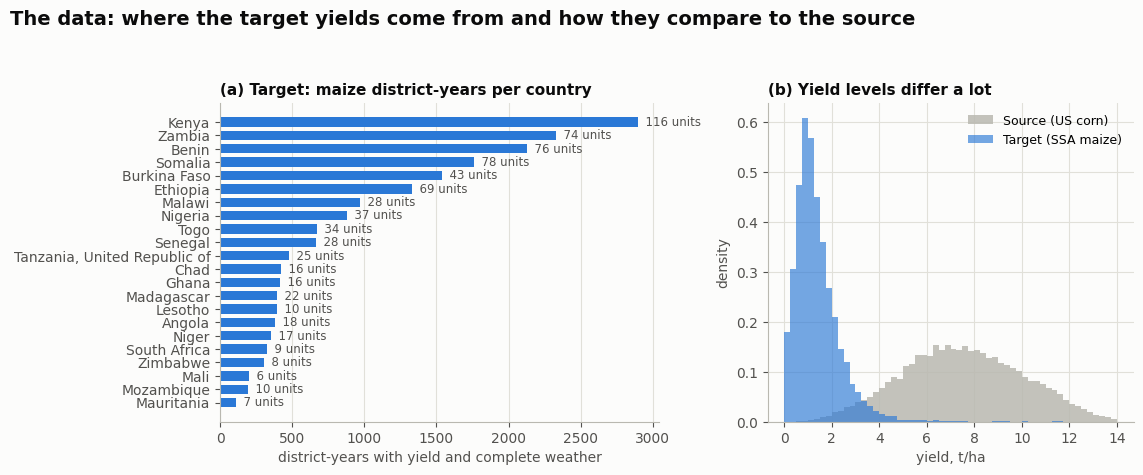

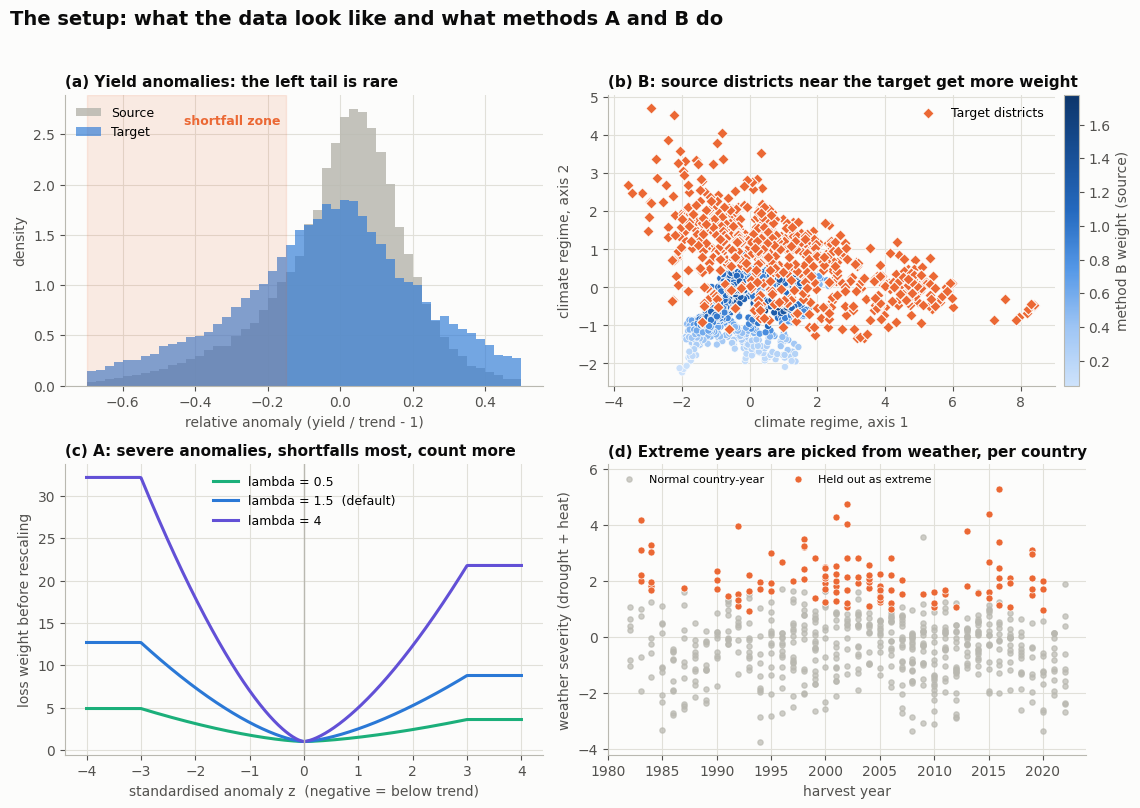

In [18]:
FIGS = {}
FIGS["data"] = fig_data(src, tgt, audit, cfg, os.path.join(cfg.out, "fig_data.png"))
FIGS["overview"] = fig_overview(payload, cfg, os.path.join(cfg.out, "fig_overview.png"))

### 8.2 Training progress
Validation loss while pre-training on the US source (left) and while fine-tuning on the target (right), one repetition. Bottom: how the paired difference between the proposed method and standard fine-tuning settles as repetitions accumulate.

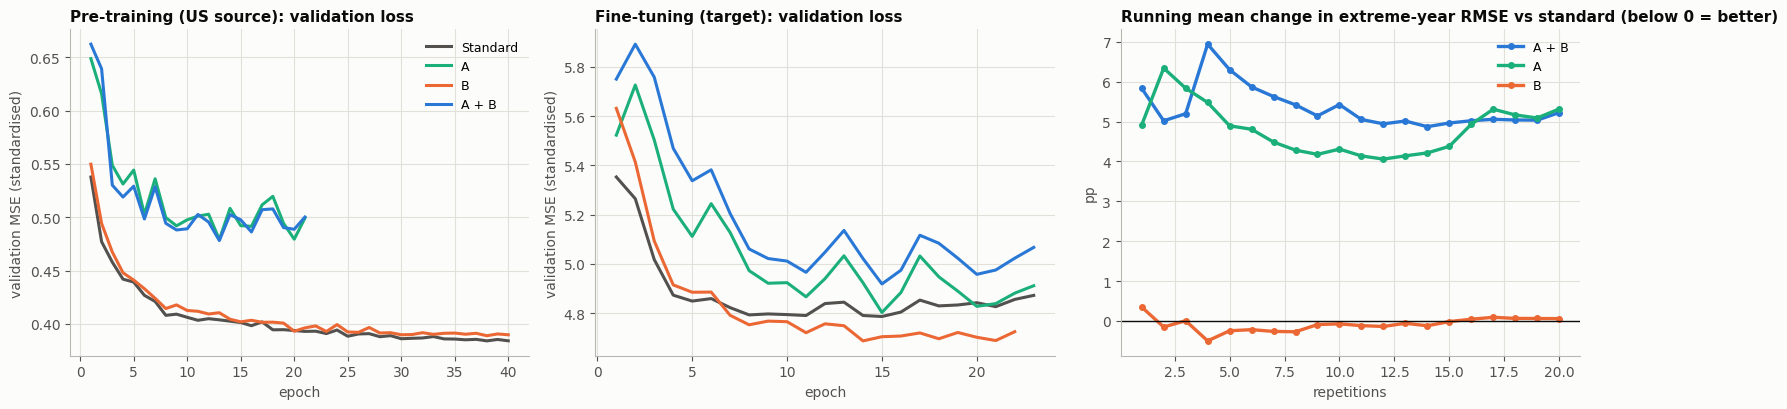

In [19]:
cur = payload["curves"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for k, lab, col in (("std", "Standard", INK2), ("A", "A", AQUA), ("B", "B", ORANGE), ("AB", "A + B", BLUE)):
    if k in cur["pre"] and len(cur["pre"][k]):
        ax[0].plot(np.arange(1, len(cur["pre"][k]) + 1), cur["pre"][k], color=col, lw=2.2, label=lab)
    if k in cur["ft"] and len(cur["ft"][k]):
        ax[1].plot(np.arange(1, len(cur["ft"][k]) + 1), cur["ft"][k], color=col, lw=2.2, label=lab)
ax[0].set_title("Pre-training (US source): validation loss"); ax[1].set_title("Fine-tuning (target): validation loss")
for a in ax[:2]:
    a.set_xlabel("epoch"); a.set_ylabel("validation MSE (standardised)")
ax[0].legend()
piv = res[(res.n_ft == cfg.main_ft) & (res.split == "extreme")].pivot(index="rep", columns="method", values="rmse_pp")
for key, col, lab in (("AB", BLUE, "A + B"), ("A", AQUA, "A"), ("B", ORANGE, "B")):
    d = (piv[key] - piv["std"]).values
    ax[2].plot(np.arange(1, len(d) + 1), np.cumsum(d) / np.arange(1, len(d) + 1), color=col, lw=2.4, marker="o", ms=4, label=lab)
ax[2].axhline(0, color=INK, lw=1)
ax[2].set_title("Running mean change in extreme-year RMSE vs standard (below 0 = better)")
ax[2].set_xlabel("repetitions"); ax[2].set_ylabel("pp"); ax[2].legend()
plt.tight_layout(); plt.show()

### 8.3 Headline comparison, ablation and data-scarcity curves

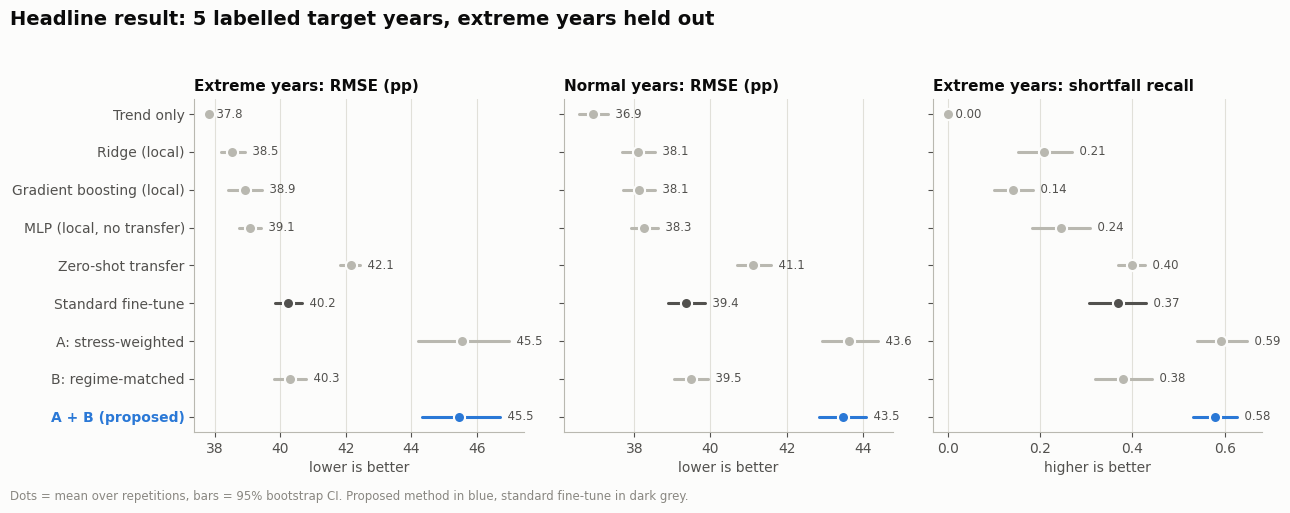

,method,RMSE (pp),RMSE (t/ha),Bias (pp),Shortfall recall
0,Trend only,37.840,0.470,7.900,0.000
1,Ridge (local),38.540,0.490,1.580,0.210
2,Gradient boosting (local),38.920,0.500,5.000,0.140
3,"MLP (local, no transfer)",39.080,0.500,1.380,0.240
4,Zero-shot transfer,42.150,0.550,-1.840,0.400
5,Standard fine-tune,40.230,0.520,-1.590,0.370
6,A: stress-weighted,45.550,0.630,-12.350,0.590
7,B: regime-matched,40.290,0.520,-2.100,0.380
8,A + B (proposed),45.460,0.620,-11.300,0.580


,method,RMSE (pp),RMSE (t/ha),Bias (pp),Shortfall recall
0,Trend only,36.910,0.440,-2.310,0.000
1,Ridge (local),38.110,0.470,-1.880,0.060
2,Gradient boosting (local),38.110,0.470,-0.850,0.050
3,"MLP (local, no transfer)",38.270,0.480,-2.880,0.100
4,Zero-shot transfer,41.120,0.530,-0.570,0.200
5,Standard fine-tune,39.350,0.500,-3.140,0.170
6,A: stress-weighted,43.650,0.580,-7.220,0.340
7,B: regime-matched,39.480,0.500,-3.430,0.180
8,A + B (proposed),43.480,0.580,-6.360,0.340


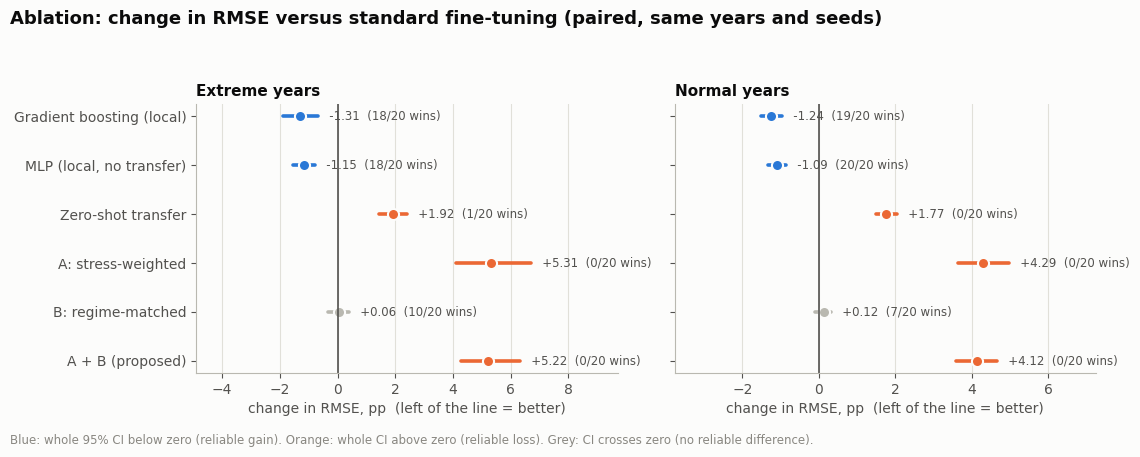

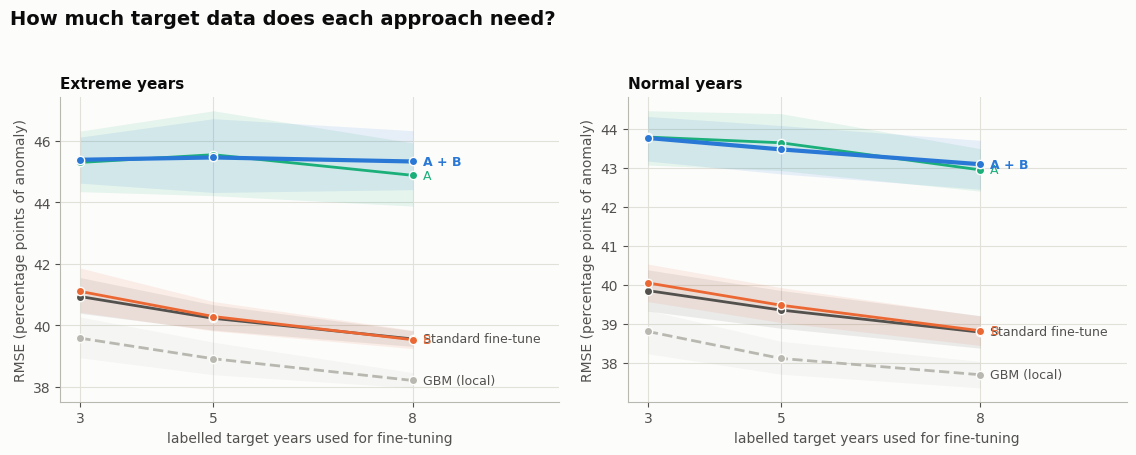

In [20]:
FIGS["main"] = fig_main(res, cfg, os.path.join(cfg.out, "fig_main.png"))
display(summary_table(res, cfg.main_ft, "extreme").round(2)[["method", "RMSE (pp)", "RMSE (t/ha)", "Bias (pp)", "Shortfall recall"]])
display(summary_table(res, cfg.main_ft, "normal").round(2)[["method", "RMSE (pp)", "RMSE (t/ha)", "Bias (pp)", "Shortfall recall"]])
FIGS["forest"] = fig_forest(res, cfg, os.path.join(cfg.out, "fig_forest.png"))
FIGS["scarcity"] = fig_scarcity(res, cfg, os.path.join(cfg.out, "fig_scarcity.png"))

### 8.4 Classification of shortfall years
A shortfall is a yield anomaly below the threshold (default −15%). Regression models are turned into classifiers by thresholding the predicted anomaly and by ranking on the negated prediction (ROC-AUC); a gradient-boosting classifier is trained directly on the same labelled target rows.

--- shortfall classification, extreme years (mean over repetitions, 5 labelled target years)


,method,ROC-AUC,Avg precision,Recall,Precision,F1
0,Ridge (local),0.513,0.395,0.209,0.381,0.249
1,Gradient boosting (local),0.514,0.410,0.142,0.429,0.196
2,MLP (local),0.516,0.406,0.245,0.399,0.280
3,"Direct classifier (GBM, local)",0.532,0.421,0.544,0.410,0.457
4,Zero-shot transfer,0.515,0.402,0.399,0.401,0.397
5,Standard fine-tune,0.523,0.410,0.368,0.410,0.373
6,A: stress-weighted,0.533,0.418,0.593,0.408,0.478
7,B: regime-matched,0.526,0.411,0.379,0.413,0.382
8,A + B (proposed),0.538,0.426,0.578,0.411,0.477


--- shortfall classification, normal years (mean over repetitions, 5 labelled target years)


,method,ROC-AUC,Avg precision,Recall,Precision,F1
0,Ridge (local),0.515,0.283,0.065,0.285,0.099
1,Gradient boosting (local),0.518,0.288,0.050,0.312,0.083
2,MLP (local),0.521,0.290,0.098,0.316,0.143
3,"Direct classifier (GBM, local)",0.538,0.297,0.442,0.299,0.355
4,Zero-shot transfer,0.521,0.288,0.198,0.297,0.235
5,Standard fine-tune,0.519,0.289,0.170,0.301,0.211
6,A: stress-weighted,0.532,0.298,0.344,0.301,0.313
7,B: regime-matched,0.518,0.287,0.176,0.295,0.216
8,A + B (proposed),0.533,0.302,0.335,0.304,0.314


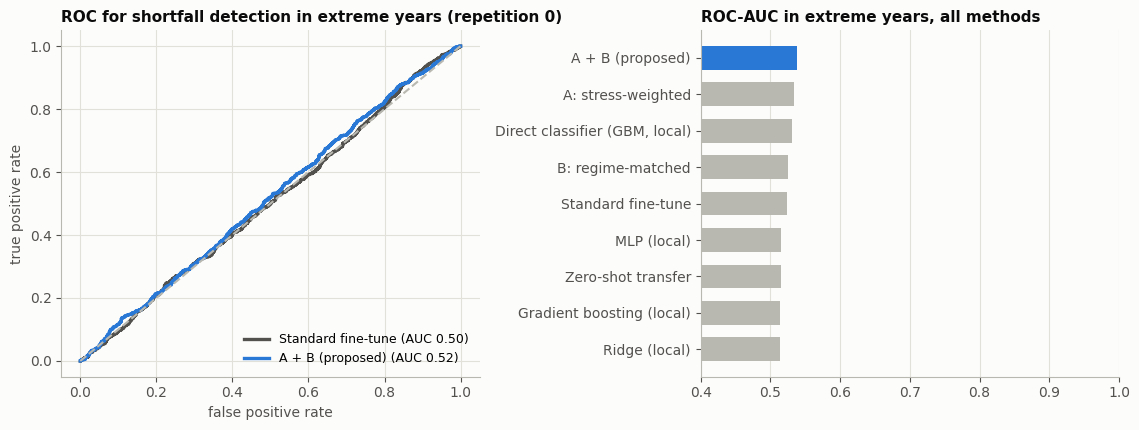

In [21]:
for split in ("extreme", "normal"):
    print(f"--- shortfall classification, {split} years (mean over repetitions, {cfg.main_ft} labelled target years)")
    display(class_table(res, cfg.main_ft, split).round(3))

p = payload["preds"]; pos = p["true"] < cfg.shortfall_thr
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
if pos.any() and (~pos).any():
    for k, lab, col in (("std", "Standard fine-tune", INK2), ("AB", "A + B (proposed)", BLUE)):
        fpr, tpr, _ = roc_curve(pos, -p[k]); ax[0].plot(fpr, tpr, color=col, lw=2.4, label=f"{lab} (AUC {roc_auc_score(pos, -p[k]):.2f})")
    ax[0].plot([0, 1], [0, 1], color=GREY, ls="--")
    ax[0].set_title("ROC for shortfall detection in extreme years (repetition 0)"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].legend(loc="lower right")
ct = class_table(res, cfg.main_ft, "extreme").set_index("method")["ROC-AUC"].dropna().sort_values()
ax[1].barh(ct.index, ct.values, color=[BLUE if "proposed" in i else GREY for i in ct.index], height=0.65)
ax[1].set_xlim(0.4, 1.0); ax[1].set_title("ROC-AUC in extreme years, all methods"); ax[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 8.5 Predictions, uncertainty (method D), sensitivity and where it helps

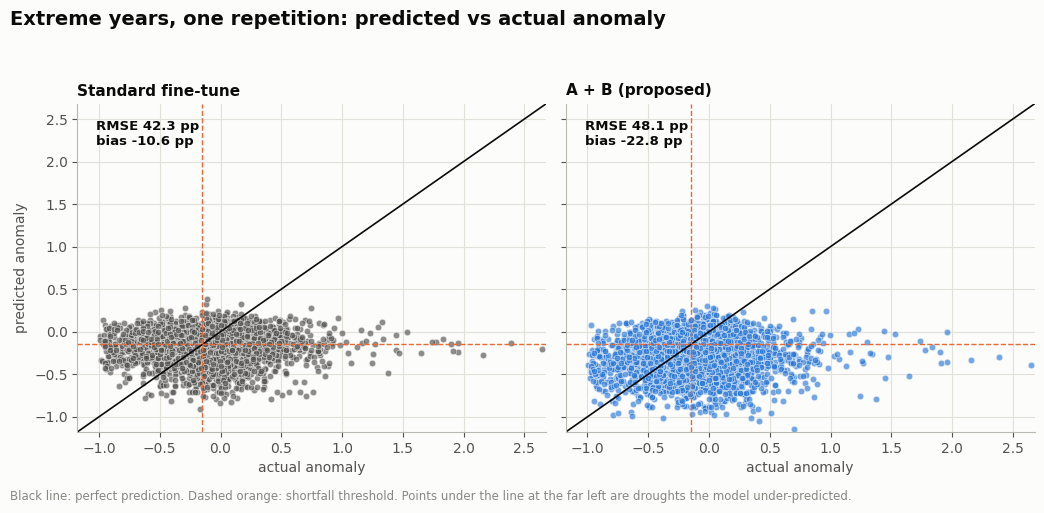

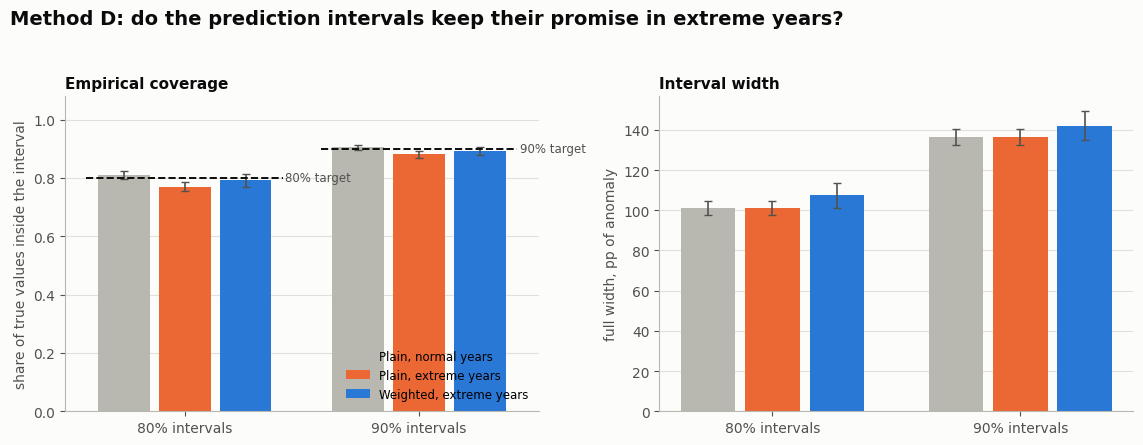

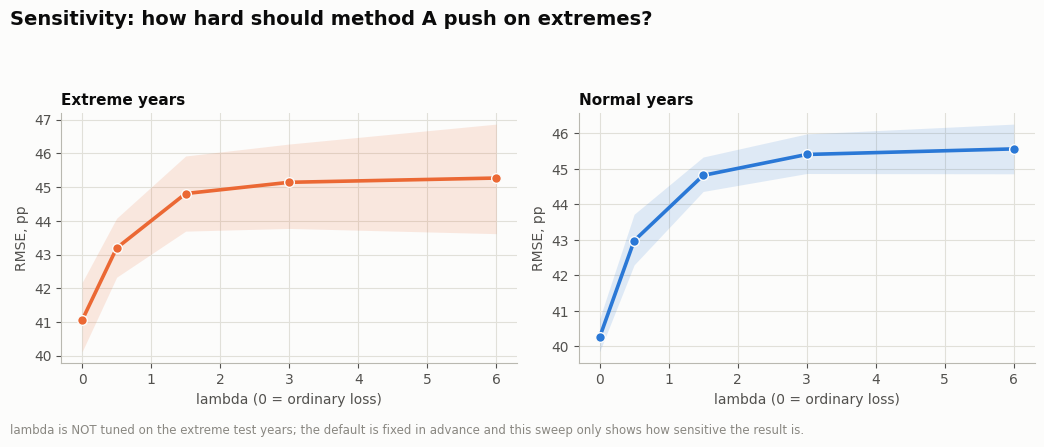

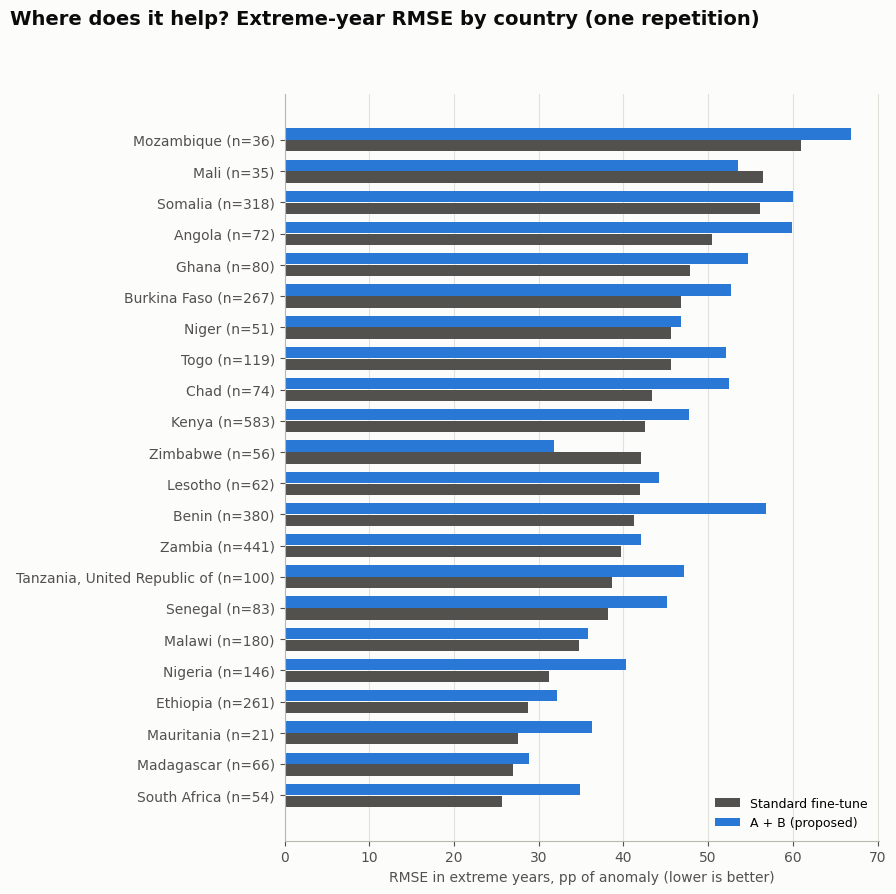

,n,std,AB
country,,,
South Africa,54,25.670,34.830
Madagascar,66,26.970,28.880
Mauritania,21,27.600,36.320
Ethiopia,261,28.680,32.120
Nigeria,146,31.190,40.300
Malawi,180,34.760,35.790
Senegal,83,38.200,45.160
"Tanzania, United Republic of",100,38.640,47.130
Zambia,441,39.680,42.050


In [22]:
FIGS["scatter"] = fig_scatter(payload, cfg, os.path.join(cfg.out, "fig_scatter.png"))
FIGS["conformal"] = fig_conformal(conf, cfg, os.path.join(cfg.out, "fig_conformal.png"))
FIGS["sweep"] = fig_sweep(sweep, cfg, os.path.join(cfg.out, "fig_sweep.png"))
bc = country_breakdown(payload, tgt, cfg)
if len(bc):
    bc.to_csv(os.path.join(cfg.out, "extreme_rmse_by_country.csv"))
    FIGS["country"] = fig_country(bc, cfg, os.path.join(cfg.out, "fig_country.png"))
    display(bc.round(2))

## 9. Optional: Transformer over the monthly weather sequence
Treats each of the six months since planting as a token (rain, Tmax, hot days) plus one static-climate token, encodes them with a small
Transformer encoder, pre-trains on the US source with the A+B weights and fine-tunes on the same target years as the main experiment
(repetition 0). **This cell only runs if PyTorch is installed and was not exercised in the environment where the notebook was written;**
if anything fails it prints a message and the rest of the notebook is unaffected.

In [23]:
TRANSFORMER_RESULT = None
try:
    import torch, torch.nn as nn, torch.nn.functional as F
    torch.manual_seed(cfg.seed)
    sp = payload["split0"]; Xs_, Xt_ = payload["Xs"], payload["Xt"]
    seq_s = torch.tensor(Xs_[:, :SEASON_MONTHS * 3].reshape(-1, SEASON_MONTHS, 3), dtype=torch.float32)
    seq_t = torch.tensor(Xt_[:, :SEASON_MONTHS * 3].reshape(-1, SEASON_MONTHS, 3), dtype=torch.float32)
    sta_s = torch.tensor(Xs_[:, SEASON_MONTHS * 3:], dtype=torch.float32)
    sta_t = torch.tensor(Xt_[:, SEASON_MONTHS * 3:], dtype=torch.float32)
    n_static = sta_s.shape[1]

    class WeatherTransformer(nn.Module):
        def __init__(self, d=32, heads=4, layers=2):
            super().__init__()
            self.tok = nn.Linear(3, d); self.sta = nn.Linear(max(n_static, 1), d)
            self.pos = nn.Parameter(torch.zeros(1, SEASON_MONTHS + 1, d))
            enc = nn.TransformerEncoderLayer(d, heads, 2 * d, 0.1, batch_first=True)
            self.enc = nn.TransformerEncoder(enc, layers); self.head = nn.Linear(d, 1)
        def forward(self, seq, sta):
            t = torch.cat([self.sta(sta).unsqueeze(1), self.tok(seq)], 1) + self.pos
            return self.head(self.enc(t).mean(1)).squeeze(-1)

    def fit(model, seq, sta, y, w, epochs, lr, ref=None, l2sp=0.0):
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        y, w = torch.tensor(y, dtype=torch.float32), torch.tensor(w / w.mean(), dtype=torch.float32)
        for ep in range(epochs):
            model.train(); perm = torch.randperm(len(y))
            for i in range(0, len(y), 256):
                b = perm[i:i + 256]
                loss = (F.huber_loss(model(seq[b], sta[b]), y[b], reduction="none", delta=cfg.huber_delta) * w[b]).mean()
                if ref is not None:
                    loss = loss + l2sp * sum(((p - r) ** 2).sum() for p, r in zip(model.parameters(), ref))
                opt.zero_grad(); loss.backward(); opt.step()
        return model

    net = WeatherTransformer()
    tr = sp["tr_idx"]
    fit(net, seq_s[tr], sta_s[tr], payload["z_s"][tr], payload["wAB"][tr], 12 if QUICK else 25, 1e-3)
    ref = [p.detach().clone() for p in net.parameters()]
    m_ft = sp["m_ft"]; zf = sp["a_t"][m_ft] / payload["sigma_ref"]
    fit(net, seq_t[m_ft], sta_t[m_ft], zf, sp["wA_f"], 30, 3e-4, ref=ref, l2sp=cfg.l2sp)
    net.eval()
    with torch.no_grad():
        pred = net(seq_t, sta_t).numpy() * payload["sigma_ref"]
    TRANSFORMER_RESULT = {}
    for split, m in (("extreme", sp["m_ext"]), ("normal", sp["m_nrm"])):
        TRANSFORMER_RESULT[split] = metrics(sp["a_t"][m], pred[m], tdf.trend.values[m], cfg.shortfall_thr)
    r0 = res[(res.rep == 0) & (res.n_ft == cfg.main_ft)]
    cmp = pd.DataFrame({sp_: {"Transformer": TRANSFORMER_RESULT[sp_]["rmse_pp"],
                              "Standard fine-tune (MLP)": r0[(r0.method == "std") & (r0.split == sp_)].rmse_pp.iloc[0],
                              "A + B (MLP)": r0[(r0.method == "AB") & (r0.split == sp_)].rmse_pp.iloc[0]} for sp_ in ("extreme", "normal")})
    print("RMSE (pp), repetition 0 only - one run, so treat differences as indicative, not conclusive:")
    display(cmp.round(2))
except ImportError:
    print("PyTorch is not installed - skipping the optional Transformer (pip install torch to enable).")
except Exception as e:
    print("Optional Transformer skipped because of an error:", repr(e))

RMSE (pp), repetition 0 only - one run, so treat differences as indicative, not conclusive:


,extreme,normal
Transformer,47.240,42.380
Standard fine-tune (MLP),42.310,37.700
A + B (MLP),48.150,41.820


## 10. Conclusion

In [24]:
n = cfg.main_ft
lines = findings_text(res, conf, cfg)
dx, dn = paired_diffs(res, n, "extreme").set_index("key"), paired_diffs(res, n, "normal").set_index("key")
cx, cn = summary_table(res, n, "extreme").set_index("method"), summary_table(res, n, "normal").set_index("method")
ab_x, std_x = cx.loc["A + B (proposed)", "RMSE (pp)"], cx.loc["Standard fine-tune", "RMSE (pp)"]
loc_x = min(cx.loc[m, "RMSE (pp)"] for m in ("Ridge (local)", "Gradient boosting (local)", "MLP (local, no transfer)"))
zero_x = cx.loc["Zero-shot transfer", "RMSE (pp)"]
sig = lambda r: "reliably better" if r["hi"] < 0 else ("reliably worse" if r["lo"] > 0 else "not reliably different")
cd = conf[(conf.model == "AB") & (conf.alpha == 0.1)]
cov = {k: cd[(cd.kind == k[0]) & (cd.split == k[1])].coverage.mean() for k in (("plain", "normal"), ("plain", "extreme"), ("weighted", "extreme"))}
ct = class_table(res, n, "extreme").set_index("method")

concl = f"""
CONCLUSION (computed from this run: {cfg.n_reps} repetitions, {n} labelled target years, {payload['n_ext_cy']} extreme country-years held out)

1. Transfer vs local models. In extreme years the best local model has RMSE {loc_x:.1f} pp; zero-shot transfer from US corn {zero_x:.1f} pp;
   standard fine-tuning {std_x:.1f} pp. {'Transfer helps.' if std_x < loc_x else 'Transfer does NOT beat the best local model on this data.'}
2. The proposed A+B method: {ab_x:.1f} pp in extreme years versus {std_x:.1f} pp for standard fine-tuning; the paired difference is
   {dx.loc['AB', 'diff']:+.2f} pp [{dx.loc['AB', 'lo']:+.2f}, {dx.loc['AB', 'hi']:+.2f}] -> {sig(dx.loc['AB'])}.
   Method A alone: {sig(dx.loc['A'])} ({dx.loc['A', 'diff']:+.2f} pp). Method B alone: {sig(dx.loc['B'])} ({dx.loc['B', 'diff']:+.2f} pp).
3. Cost in ordinary years: A+B vs standard in normal years is {dn.loc['AB', 'diff']:+.2f} pp [{dn.loc['AB', 'lo']:+.2f}, {dn.loc['AB', 'hi']:+.2f}] -> {sig(dn.loc['AB'])}.
4. Shortfall classification in extreme years: ROC-AUC {ct.loc['A + B (proposed)', 'ROC-AUC']:.2f} for A+B, {ct.loc['Standard fine-tune', 'ROC-AUC']:.2f} for standard fine-tuning,
   recall {ct.loc['A + B (proposed)', 'Recall']:.2f} vs {ct.loc['Standard fine-tune', 'Recall']:.2f}.
5. Uncertainty: nominal 90% intervals covered {cov[('plain', 'normal')]:.0%} of normal-year and {cov[('plain', 'extreme')]:.0%} of extreme-year targets with plain
   conformal; shift-weighted conformal covered {cov[('weighted', 'extreme')]:.0%} in extreme years.
"""
print(concl)
open(os.path.join(cfg.out, "conclusion.txt"), "w").write(concl)
rep = write_report(cfg, res, conf, sweep, payload, FIGS, audit, tic() - t0)
print("full HTML report:", rep)


CONCLUSION (computed from this run: 20 repetitions, 5 labelled target years, 117 extreme country-years held out)

1. Transfer vs local models. In extreme years the best local model has RMSE 38.5 pp; zero-shot transfer from US corn 42.1 pp;
   standard fine-tuning 40.2 pp. Transfer does NOT beat the best local model on this data.
2. The proposed A+B method: 45.5 pp in extreme years versus 40.2 pp for standard fine-tuning; the paired difference is
   +5.22 pp [+4.27, +6.34] -> reliably worse.
   Method A alone: reliably worse (+5.31 pp). Method B alone: not reliably different (+0.06 pp).
3. Cost in ordinary years: A+B vs standard in normal years is +4.12 pp [+3.59, +4.65] -> reliably worse.
4. Shortfall classification in extreme years: ROC-AUC 0.54 for A+B, 0.52 for standard fine-tuning,
   recall 0.58 vs 0.37.
5. Uncertainty: nominal 90% intervals covered 90% of normal-year and 88% of extreme-year targets with plain
   conformal; shift-weighted conformal covered 89% in extreme years.



### How to read this conclusion
- A difference only counts if its interval excludes zero. "Not reliably different" is a legitimate result, and a careful negative is publishable: it tells readers when extreme-year-aware transfer does not help.
- Novelty. Weighted losses for extremes (ExtremeLoss, extreme-year weighting) and instance weighting for domain adaptation both exist. The defensible contribution is their **combination** applied to district-level African maize, with an extreme-year protocol based on weather only, per-country extreme years, direct shortfall classification and conformal intervals checked under shift. My confidence in the novelty is moderate.
- Data limits. NASA POWER is coarse and weak for African rainfall (CHIRPS is better: replace `fetch_weather_cell`). HarvestStat yields are harmonised official statistics with varying quality. QC-flagged outliers were kept or dropped according to `cfg.drop_qc_outliers`; rerun both ways and report both.
- Protocol limit. A year can be normal in one country and extreme in another, so regional climate-state information (for example ENSO) is not fully isolated between fine-tuning and extreme-test sets.
- Worth trying next: per-country leave-one-country-out; CHIRPS rainfall; a PyTorch version of the network; more repetitions.